# Proyecto final

## Dirección de crecimiento urbano

**Insumos:** ejes viales de la cartografía censal MGN (CPV2021) y de la base cartográfica 2014 (GDB), INEC, disponibles en https://www.ecuadorencifras.gob.ec/documentos/web-inec/Geografia_Estadistica/Micrositio_geoportal/index.html, sin sentido de circulación ni topología dirigida; y las delimitaciones de áreas de cada base (`aream_a` y `GEO_AREAM2014`).

**Pregunta:** ¿es factible, a partir de las geometrías de los ejes, decir sobre qué eje (N–S o E–O) **está orientada** o **se extiende** una ciudad, y si eso ayuda a anticipar su **crecimiento**?

| Familia | Qué responde | Herramientas |
|---|---|---|
| **Forma / orientación** de la red | ¿Hacia dónde *apuntan* las calles? | azimut axial, rosa de orientaciones, entropía y orden (Boeing, 2019), componente N–S/E–O |
| **Extensión espacial** de la red  | ¿Hacia dónde *se alarga* la mancha vial? | elipse de desviación estándar, sectores y anillos desde un centro |

**Flujo.** Las dos versiones (2014 y 2021) siguen la misma secuencia: carga (2) → validación (3) → segmentos (4) → parámetros geométricos (6) → EDA (7–7.2) → resumen por área (7.3). Sobre esa base se analiza la extensión de un área de ejemplo (8), se construyen las variables de crecimiento (9) y se entrenan los modelos (10).

### Entorno
Librerías requeridas: `geopandas>=0.14`, `shapely>=2`, `pyogrio`, `pyarrow`, `matplotlib` y `scikit-learn`.

In [1]:
#!pip install geopandas shapely pyogrio pyarrow matplotlib scikit-learn

In [2]:
from pathlib import Path

import numpy as np

import pandas as pd
import geopandas as gpd
import shapely # para trabajar con geometrías planas, motor de gpd
import pyogrio # para lectura en lotes de datos vectoriales, puede usar sql
import pyarrow.parquet as pq # esquema del parquet sin leer los datos
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.inspection import permutation_importance

### 1. Parámetros
Todas las variables configurables del notebook, agrupadas por sección.

In [3]:
# --- 2. Preparación de insumos (solo con PREPARAR = True) ---
PREPARAR    = False           # True = ejecuta 2.1–2.4 y genera los GeoParquet (requerido tras cambiar RENOMBRAR o DELIMITACIONES); False = solo 2.5
CRS_TRABAJO = "EPSG:31992"    # SIRGAS 1995 / UTM 17S (CRS nativo de la capa MGN)

RUTA_EJES   = Path("insumos/ejes_l_mgn25.gpkg")   # Colab: Path("/content/drive/MyDrive/.../ejes_l_mgn25.gpkg")
CAPA        = "ejes_l"        # capa de ejes dentro de RUTA_EJES
FILTRO_SQL  = None            # filtro al preparar insumos; None = nacional

RUTA_GDB       = Path("insumos/GEODATABASE2014.gdb")   # carpeta .gdb
CAPA_GDB       = "GEO_EJES2014"                 # None = solo inventario (no se prepara la capa antigua)
FILTRO_SQL_GDB = FILTRO_SQL                     # revisar nombre y tipo del campo en la GDB
RENOMBRAR      = {"dpa_parroq": "parroquia",    # homologa la capa antigua con la actual (nombres ya en minúscula)
                  "dpa_tipo": "tipo_eje", "dpa_nombre": "nom_eje"}
DESCARTAR      = ["join_count", "target_fid", "shape_leng", "shape_length"]   # campos de proceso de la GDB, sin uso

CAMPO_AREA_EJE = "area"       # nombre del campo que recibe el área en los ejes
TOLERANCIA_M   = 50           # m; solo entre bases distintas (ejes antiguos vs. áreas actuales y viceversa)
DELIMITACIONES = {            # campo que se crea en los ejes: archivo y capa de áreas, campo con el nombre,
                              # código para desambiguar nombres repetidos (None = solo nombre) y base de origen
    CAMPO_AREA_EJE: {"ruta": RUTA_EJES, "capa": "aream_a",       "campo": "nom_aman",   "id": "parroq", "base": "actual"},   # clave: "nom_aman | parroq"
    "area_ant":     {"ruta": RUTA_GDB,  "capa": "GEO_AREAM2014", "campo": "DPA_NOMBRE", "id": None,     "base": "antigua"},  # solo se usa como vacío / no vacío
}

RUTA_PARQUET = {"antigua": Path("insumos/ejes_antigua.parquet"),
                "actual":  Path("insumos/ejes_actual.parquet")}

# --- Carga para el análisis ---
ANIOS         = {"antigua": 2014, "actual": 2021}   # versiones que se cargan (orden de tablas y gráficos) y su año
FILTRO_CARGA  = None          # filtro al leer el parquet, p. ej. [("provincia", "==", "17")]
AREAS_CARGA   = None          # lista de áreas a cargar con la clave completa, p. ej. ["QUITO | 170150"]; None = todas
EXCLUIR_TIPOS = []            # p. ej. ["SENDERO", "ESCALINATA"] para quedarte con la red vehicular

# --- Parámetros geométricos y EDA ---
CLASES_OR     = ["N–S", "NE–SO", "E–O", "NO–SE"]   # sectores axiales de 45°
N_BINS        = 36            # bins de 10°, como Boeing (2019)
H_MAX, H_GRID = np.log(N_BINS), np.log(4)          # entropía máxima y de cuadrícula perfecta (Boeing, 2019)
TAM_CELDA     = 1000          # m; malla de agregación (≈1000 m a nivel nacional)
FILTRO_EJEMPLO = None         # solo 7.2.1: (campo, [valores]), p. ej. (CAMPO_GRUPO, ["QUITO | 170150"]) o ("provincia", ["17"]);
                              # None = AREA_EJEMPLO o, si no está definida, el área de mayor longitud
TAM_CELDA_EJ  = 250           # m; malla de los mapas de 7.2.1 (una ciudad necesita celdas más finas)
CAMPO_GRUPO   = CAMPO_AREA_EJE   # unidad de resumen y de comparación (sección 7.3 en adelante); también "parroquia"
MIN_SEGMENTOS = 50            # grupos con menos segmentos no se resumen (entropía sesgada con n pequeño)
MIN_SEMIEJE_M = 50            # m; si el semieje menor de la elipse es menor, la red es casi lineal y no se calcula a/b

# --- Extensión espacial y comparación entre temporalidades ---
AREA_EJEMPLO = None           # valor de CAMPO_GRUPO (p. ej. "QUITO | 170150") para las secciones 8 y 9.2 (y 7.2.1 si FILTRO_EJEMPLO = None); None = el de mayor longitud
CENTRO_EXT   = None           # (x, y) en CRS_TRABAJO para anillos y sectores; None = centro medio ponderado 2014
ANCHO_ANILLO = 1000           # m; ancho de cada anillo
N_SECTORES   = 8              # sectores de 45° (N, NE, E, SE, S, SO, O, NO)
N_DIR_CREC   = 16             # sectores de la rosa de la red nueva (22,5°)

# --- Modelos ---
OBJETIVO    = "pct_expansion" # "pct_expansion", "log_pct_expansion", "tasa_crec" o "C_crec"
PREDICTORES = ["log_long_km_14", "phi_14", "R_14", "C_NS_EO_14", "sinuos_mediana_14", "log_elong_14",
               "elip_cos2_14", "elip_sin2_14", "dens_elipse_14"]
PRUEBA      = 0.25            # fracción de áreas reservada para evaluar los modelos
N_PLIEGUES  = 5               # pliegues de la validación cruzada
N_ARBOLES   = 500             # árboles del random forest
MIN_HOJA    = 2               # muestras mínimas por hoja (limita el sobreajuste con pocas áreas)
N_PERMUT    = 30              # repeticiones de la importancia por permutación
SEMILLA     = 42
OBJETIVO_DIR  = "C_crec"     # objetivo de 10.3: dirección del crecimiento (+1 hacia N y S, −1 hacia E y O)
MIN_KM_NUEVOS = 0            # km; 10.3 solo usa áreas con al menos esta longitud de red nueva (C_crec es ruidoso con poca red)
UMBRALES_KM   = [0, 0.5, 1, 2]   # km; sensibilidad del R² de 10.3 a MIN_KM_NUEVOS

# --- Gráficos ---
CMAP_AXIAL = "hsv"            # mapa de color cíclico para azimut axial (0° = 180°); alternativa: "twilight"
COLORES    = {"antigua": "#3b6ea5", "actual": "#c0392b"}   # color de cada versión
COLOR_BASE = "#9aa5b1"        # red de fondo en los mapas

### 2. Carga
La preparación (2.1–2.4) se ejecuta **una sola vez** con `PREPARAR = True`: lee los insumos originales, homologa la capa antigua, asigna las áreas y exporta un GeoParquet por versión. Después, con `PREPARAR = False`, el notebook solo lee los parquet (2.5).

#### 2.1 Capa actual (GPKG)
- Descripción del conjunto de datos (sin cargar geometrías).
- Carga de la capa con `pyogrio` + Arrow, que es la vía más rápida para cientos de miles de líneas.
- `FILTRO_SQL` limita lo que se prepara (prueba: Pichincha, código 17; `None` = nacional).

**CRS.** Todo se lleva a `CRS_TRABAJO` (EPSG:31992, SIRGAS 1995 / UTM 17S) durante la preparación: ejes actuales (2.1, ya vienen en ese CRS), ejes antiguos (2.2, vienen en EPSG:32717, WGS 84 / UTM 17S) y las dos delimitaciones de áreas (2.3). Los GeoParquet quedan en `CRS_TRABAJO`, por lo que la carga (2.5) no reproyecta.

In [4]:
if PREPARAR:
    capas = pyogrio.list_layers(RUTA_EJES)
    CAPA = CAPA or capas[0][0] # se lee: None or "ejes_l"
    info = pyogrio.read_info(RUTA_EJES, layer=CAPA)
    print("Conjunto de datos MGN:\n\nCapas:", capas.tolist(), "\n")
    print(f"Capa '{CAPA}': {info['features']:,} entidades | {info['geometry_type']} | {info['crs']}\n")
    print("Campos:", list(info["fields"]), "\n")
    #
    g = gpd.read_file(RUTA_EJES, layer=CAPA, where=FILTRO_SQL, engine="pyogrio",
                      use_arrow=True, fid_as_index=True) # arrow agiliza la carga por bloques del gdf
    if g.crs != CRS_TRABAJO:   # la capa MGN ya viene en CRS_TRABAJO; solo reproyecta si cambia el insumo
        g = g.to_crs(CRS_TRABAJO)
    #
    insumos = {"actual": g}
    display(g.head())

#### 2.2 Capa antigua (GDB)
- La `.gdb` es una **carpeta**; la ruta apunta a la carpeta completa. GDAL la lee con el driver `OpenFileGDB` (no requiere ArcGIS).
- Muestra el inventario de capas; si `CAPA_GDB` tiene nombre, la prepara como versión `"antigua"`.
- Homologación: campos en minúscula, se descartan los campos de proceso (`DESCARTAR`), `RENOMBRAR` para que la capa antigua tenga los mismos nombres que la actual (`parroquia`, `tipo_eje`, `nom_eje`), geometría 2D (sin Z/M), `CRS_TRABAJO` y solo líneas.
- **Revisar el CRS que reporta el inventario.** Si la capa antigua está en PSAD56 o tiene un CRS mal declarado, el desplazamiento es sistemático y se corrige con el CRS correcto, no con tolerancia (ver 2.3).
- Si hay geometrías curvas (`MultiCurve`) y la lectura falla: `ogr2ogr -nlt MULTILINESTRING salida.gpkg entrada.gdb capa`.

In [5]:
if PREPARAR and RUTA_GDB.exists():
    # Inventario: capas, geometría, nº de entidades, CRS y campos
    inv = []
    for nombre, tipo in pyogrio.list_layers(RUTA_GDB):
        i = pyogrio.read_info(RUTA_GDB, layer=nombre)
        inv.append({"capa": nombre, "geometria": tipo, "entidades": i["features"],
                    "crs": i["crs"], "campos": list(i["fields"])})
    display(pd.DataFrame(inv).set_index("capa"))

if PREPARAR and RUTA_GDB.exists() and CAPA_GDB:
    g = gpd.read_file(RUTA_GDB, layer=CAPA_GDB, where=FILTRO_SQL_GDB, engine="pyogrio",
                      use_arrow=True, fid_as_index=True)
    # Homologación con la estructura que usa el notebook
    g = g.rename(columns=str.lower).rename(columns=RENOMBRAR).drop(columns=DESCARTAR, errors="ignore")
    g = g.set_geometry(shapely.force_2d(g.geometry.values), crs=g.crs)   # quita Z/M
    if g.crs is None:
        print("La capa no tiene CRS: asignarlo con g.set_crs(...) antes de continuar")
    elif g.crs != CRS_TRABAJO:
        g = g.to_crs(CRS_TRABAJO)
    g = g[g.geom_type.isin(["LineString", "MultiLineString"])]
    insumos["antigua"] = g
    print(f"Capa '{CAPA_GDB}': {len(g):,} entidades | {g.crs.to_string() if g.crs else 'SIN CRS'}")
    print("Campos:", list(g.columns.drop("geometry")))
    display(g.head())

#### 2.3 Unión espacial: nombre de áreas
Cada eje que **toca o está dentro** de un área, toma su nombre. Se aplican las **dos delimitaciones** a **las dos versiones** de ejes:

| Campo en los ejes | Delimitación | Uso |
|---|---|---|
| `area` (`CAMPO_AREA_EJE`) | actual (`aream_a`) | marco común para comparar ambas fechas; filtro al cargar |
| `area_ant` | antigua (`GEO_AREAM2014`) | mancha anterior: en los ejes actuales, `area_ant` vacío = expansión posterior |

- Si un eje toca **varias** áreas, se asigna la que contiene la mayor longitud del eje.
- **Tolerancia (`TOLERANCIA_M`)** solo cuando ejes y delimitación vienen de bases distintas, que es donde aparece el desplazamiento: los ejes sin área toman la más cercana a menos de esa distancia y quedan marcados en `<campo>_por_tol`.
- Mientras `campo` sea `None`, la celda muestra los campos de esa capa para elegir el que tiene el nombre del área.
- **Nombres repetidos.** `area` es la clave de agrupación de las secciones 7.3–10. Si dos polígonos lejanos comparten nombre (localidades homónimas en provincias distintas), sus redes se mezclarían. La celda lista esos nombres con la distancia entre sus polígonos; si son áreas distintas, se define `id` en `DELIMITACIONES` y la clave pasa a ser `nombre | código`.

In [6]:
if PREPARAR:
    diag = []
    for destino, d in DELIMITACIONES.items():
        if d["campo"] is None:   # campo aún no definido: muestra los disponibles
            print(f"Capa '{d['capa']}': definir 'campo'. Primeras filas:")
            display(gpd.read_file(d["ruta"], layer=d["capa"], ignore_geometry=True, rows=5, engine="pyogrio"))
            continue
        cols = [d["campo"]] + ([d["id"]] if d["id"] else [])
        areas = gpd.read_file(d["ruta"], layer=d["capa"], columns=cols, engine="pyogrio").to_crs(CRS_TRABAJO)
        if d["id"]:   # clave única: nombre | código
            areas[d["campo"]] = areas[d["campo"]].astype(str) + " | " + areas[d["id"]].astype(str)
        areas = areas[[d["campo"], "geometry"]].rename(columns={d["campo"]: destino}).reset_index(drop=True)
        areas = areas.set_geometry(shapely.make_valid(areas.geometry.values), crs=areas.crs)
        bandera = f"{destino}_por_tol"

        # 0) Nombres en más de un polígono: distancia máxima entre sus centroides
        if destino == CAMPO_AREA_EJE:
            c = areas.geometry.centroid
            rep = areas.assign(cx=c.x, cy=c.y)[areas[destino].duplicated(keep=False)]
            if len(rep):
                rep = rep.groupby(destino).agg(poligonos=("cx", "size"),
                                               dx=("cx", lambda s: s.max() - s.min()), dy=("cy", lambda s: s.max() - s.min()))
                rep["dist_max_km"] = np.hypot(rep.dx, rep.dy) / 1000
                print(f"'{d['capa']}': {len(rep)} nombres en más de un polígono; "
                      f"{(rep.dist_max_km > 10).sum()} con polígonos a más de 10 km (probables homónimos)")
                display(rep.drop(columns=["dx", "dy"]).sort_values("dist_max_km", ascending=False).head(10).round(1))

        for version, g in insumos.items():
            g = g.drop(columns=[destino, bandera], errors="ignore")
            # 1) Ejes que tocan o están dentro de un área
            par = gpd.sjoin(g[["geometry"]], areas, predicate="intersects", how="inner")
            varias = par.index.duplicated(keep=False)
            n_varias = int(np.unique(par.index[varias]).size)
            L_comp = np.full(len(par), np.inf)                      # longitud compartida (solo si toca varias)
            L_comp[varias] = shapely.length(shapely.intersection(
                par.geometry.values[varias], areas.geometry.values[par.index_right.to_numpy()[varias]]))
            par["L_comp"] = L_comp
            par = par.sort_values("L_comp", ascending=False, kind="stable")
            par = par[~par.index.duplicated(keep="first")]
            g[destino] = par[destino].reindex(g.index)
            g[bandera] = False

            # 2) Entre bases distintas: ejes sin área a menos de la tolerancia toman la más cercana
            tol = TOLERANCIA_M if version != d["base"] else 0
            sin = g[destino].isna()
            if tol > 0 and sin.any():
                cerca = gpd.sjoin_nearest(g.loc[sin, ["geometry"]], areas, max_distance=tol, how="inner")
                cerca = cerca[~cerca.index.duplicated(keep="first")]
                g.loc[cerca.index, destino] = cerca[destino]
                g.loc[cerca.index, bandera] = True

            # 3) Diagnóstico: distancia de los ejes que siguen sin área a la más cercana
            sin = g[destino].isna()
            dist_sin = (gpd.sjoin_nearest(g.loc[sin, ["geometry"]], areas, distance_col="d").groupby(level=0).d.min()
                        if sin.any() else pd.Series(dtype=float))
            diag.append({"delimitación": f"{destino} ({d['capa']})", "versión": version, "ejes": len(g),
                         "toca o dentro": int(g[destino].notna().sum() - g[bandera].sum()),
                         "en varias áreas": n_varias, "por tolerancia": int(g[bandera].sum()),
                         "sin área": int(sin.sum()),
                         "sin área: dist. mediana (m)": round(dist_sin.median(), 1) if len(dist_sin) else None,
                         "sin área: dist. P5 (m)": round(dist_sin.quantile(.05), 1) if len(dist_sin) else None})
            insumos[version] = g
    if diag:
        display(pd.DataFrame(diag).set_index(["delimitación", "versión"]))

#### 2.4 Exportación a GeoParquet
Un archivo por versión (`RUTA_PARQUET`), con los campos homologados, los campos de área (`area`, `area_ant`) con sus marcas `_por_tol`, y `provincia` (dos primeros dígitos de `parroquia`; en la capa antigua existe gracias a `RENOMBRAR`), para filtrar al cargar. Se guarda con compresión `zstd` y la columna `bbox` (GeoParquet 1.1), que permite leer solo una zona.

In [7]:
if PREPARAR:
    for version, g in insumos.items():
        g = g.copy()
        if "parroquia" in g.columns:
            g["provincia"] = g["parroquia"].astype(str).str.zfill(6).str[:2]
        RUTA_PARQUET[version].parent.mkdir(parents=True, exist_ok=True)
        g.to_parquet(RUTA_PARQUET[version], compression="zstd", write_covering_bbox=True)
        print(f"{version}: {len(g):,} ejes -> {RUTA_PARQUET[version]} "
              f"({RUTA_PARQUET[version].stat().st_size / 1e6:.1f} MB)")

#### 2.5 Carga para el análisis (GeoParquet)
Lee **las dos versiones** (`ANIOS`) en el diccionario `gdf`. `FILTRO_CARGA` y `AREAS_CARGA` filtran al leer, sin cargar el resto del archivo; si una versión no tiene el campo del filtro, ese filtro no se le aplica y se avisa. `EXCLUIR_TIPOS` se aplica a las dos versiones.

In [8]:
filtros = list(FILTRO_CARGA or [])
if AREAS_CARGA:
    filtros.append((CAMPO_AREA_EJE, "in", list(AREAS_CARGA)))

gdf = {}
for version in ANIOS:
    cols = pq.read_schema(RUTA_PARQUET[version]).names
    f = [t for t in filtros if t[0] in cols]
    if len(f) < len(filtros):
        print(f"Aviso: '{version}' no tiene {[t[0] for t in filtros if t[0] not in cols]}; volver a preparar con PREPARAR = True")
    g = gpd.read_parquet(RUTA_PARQUET[version], filters=f or None).drop(columns="bbox", errors="ignore")
    g = g.rename(columns=RENOMBRAR).drop(columns=DESCARTAR, errors="ignore")   # por si el parquet es anterior a RENOMBRAR
    if EXCLUIR_TIPOS and "tipo_eje" in g.columns:
        g = g[~g["tipo_eje"].isin(EXCLUIR_TIPOS)]
    gdf[version] = g.rename_axis("id_eje")
    print(f"{version} ({ANIOS[version]}): {len(g):,} entidades | {g.crs.to_string()} | filtros: {f or 'ninguno'}")
gdf["actual"].head()

antigua (2014): 399,592 entidades | EPSG:31992 | filtros: ninguno
actual (2021): 608,882 entidades | EPSG:31992 | filtros: ninguno


,fcode,parroquia,nom_par,tipo_eje,nom_eje,cod_tip_ej,fuente,anio,geometry,area,area_por_tol,area_ant,area_ant_por_tol,provincia
id_eje,,,,,,,,,,,,,,
1,BB007,100254,SAN ROQUE,SENDERO,17,SEND.,CPV2021,2020,"MULTILINESTRING ((807827.308 10032991.266, 807...",SAN ROQUE | 100254,False,SAN ROQUE,False,10
2,BB007,100254,SAN ROQUE,CALLE,SIMON BOLIVAR,CL.,CPV2021,2020,"MULTILINESTRING ((807827.308 10032991.266, 807...",SAN ROQUE | 100254,False,SAN ROQUE,False,10
3,BB007,100254,SAN ROQUE,PASAJE,16,PSJE.,CPV2021,2020,"MULTILINESTRING ((807823.073 10033102.232, 807...",SAN ROQUE | 100254,False,SAN ROQUE,False,10
4,BB007,100254,SAN ROQUE,CALLE,SIMON BOLIVAR,CL.,CPV2021,2020,"MULTILINESTRING ((807823.073 10033102.232, 807...",SAN ROQUE | 100254,False,SAN ROQUE,False,10
5,BB007,100254,SAN ROQUE,CALLE,SIMON BOLIVAR,CL.,CPV2021,2020,"MULTILINESTRING ((807840.547 10033166.877, 807...",SAN ROQUE | 100254,False,SAN ROQUE,False,10


In [9]:
pd.concat({v: g.drop(columns="geometry").describe(include="all").T for v, g in gdf.items()})

count unique                 top    freq
antigua parroquia         399592   1017              090150   45511
        nom_eje           399592  43033             CALLE 2    4918
        tipo_eje          399592     18               CALLE  293792
        fuente            399592      8            ORTOFOTO  357381
        area              398211   1585  GUAYAQUIL | 090150   44937
        area_por_tol      399592      2               False  398470
        area_ant          399584   1398           GUAYAQUIL   45346
        area_ant_por_tol  399592      1               False  399592
        provincia         399592     25                  09   81663
actual  fcode             608882      1               BB007  608882
        parroquia         608882   1043              090150   58614
        nom_par           608882    984           GUAYAQUIL   58614
        tipo_eje          608882     24               CALLE  428249
        nom_eje           608882  45976                   A   12126
        cod_tip_ej        608882     23                 CL.  428291
        fuente            608882      3             CPV2021  488917
        anio              608882      5                2021  361163
        area              608568   1836  GUAYAQUIL | 090150   58401
        area_por_tol      608882      1               False  608882
        area_ant          559563   1398               QUITO   57147
        area_ant_por_tol  608882      2               False  597656
        provincia         608882     24                  09  115939

### 3. Validación de geometrías
Revisión de CRS, geometrías nulas, vacías, inválidas, multipartes y duplicadas, por versión.

In [10]:
val = {}
for version, g in gdf.items():
    geoms = g.geometry.values # se genera un arreglo de geometrías
    n_partes = shapely.get_num_geometries(geoms) # Cuenta las geometrías por entidad
    dup = pd.Series(shapely.to_wkb(shapely.normalize(geoms))).duplicated()
    val[version] = {
        "CRS": g.crs.to_string() if g.crs else "SIN CRS",
        "CRS geográfico (grados)": bool(g.crs and g.crs.is_geographic),
        "Entidades": len(g),
        "Geometrías nulas": int(g.geometry.isna().sum()),
        "Geometrías vacías": int(g.geometry.is_empty.sum()),
        "Geometrías inválidas": int((~g.geometry.is_valid).sum()),
        "Multipartes con >1 parte": int((n_partes > 1).sum()),
        "Duplicados geométricos exactos": int(dup.sum()),
    }
    print(f"{version}:", g.geom_type.value_counts().to_dict())
val = pd.DataFrame(val)
val

antigua: {'MultiLineString': 399592}
actual: {'MultiLineString': 608882}


,antigua,actual
CRS,EPSG:31992,EPSG:31992
CRS geográfico (grados),False,False
Entidades,399592,608882
Geometrías nulas,0,0
Geometrías vacías,0,0
Geometrías inválidas,0,1
Multipartes con >1 parte,0,1705
Duplicados geométricos exactos,0,1


### 4. De multipartes a segmentos simples
Cada `MultiLineString` se intenta fusionar (`line_merge`) y luego se separa en partes. El resultado de cada versión queda en el diccionario `ejes`, que es el insumo de todas las secciones siguientes.

In [11]:
ejes = {}
for version, g in gdf.items():
    g = g.copy()
    g[g.geometry.name] = shapely.line_merge(g.geometry.values)
    s = g.explode(index_parts=True)
    s.index = s.index.set_names(["id_eje", "id_parte"])
    s = s.reset_index()
    ejes[version] = s[s.geom_type == "LineString"].reset_index(drop=True)

pd.DataFrame({v: {"Entidades": len(gdf[v]), "Segmentos LineString": len(s),
                  "Multipartes con >1 parte": int((shapely.get_num_geometries(s.geometry.values) > 1).sum())}
              for v, s in ejes.items()})

,antigua,actual
Entidades,399592,608882
Segmentos LineString,399592,610658
Multipartes con >1 parte,0,0


### 5. Funciones de cálculo

**Convenciones angulares.** Azimut medido desde el norte, en sentido horario. Como los ejes no tienen sentido, la orientación es **axial**: θ ∈ [0°, 180°), y θ ≡ θ + 180°. Para promediar datos axiales se **duplica el ángulo** (2θ), se promedia como dato circular y se divide entre 2 (Krumbein, 1939; Mardia & Jupp, 2000, cap. 9).

**Por segmento** (`metricas_geometricas`, sección 6):

| Campo | Definición | Uso | Fuente |
|---|---|---|---|
| `eda_long_m` | longitud planar | peso de todas las estadísticas | — |
| `eda_n_vert` | número de vértices | EDA (detalle de digitalización) | — |
| `eda_cuerda_m` | distancia recta entre extremos | EDA; base de la sinuosidad | — |
| `eda_sinuos` | longitud / cuerda (≥1) | EDA, resumen por área, modelos | Mueller (1968); *circuity*: Giacomin & Levinson (2015), Boeing (2019) |
| `eda_cerrada` | lazo cerrado (cuerda ≈ 0) | alertas | — |
| `eda_az_cuerda` | azimut axial extremo→extremo | rosas, entropía, `C_NS_EO` | Boeing (2019): orientación de la arista *u→v* |
| `eda_az_medio` | azimut axial medio de los sub-tramos, ponderado por longitud | `eda_clase_or` | Mardia & Jupp (2000) |
| `eda_coher` | longitud media resultante *R̄* de 2θ: 1 = recto, 0 = orientaciones que se anulan | EDA | Mardia & Jupp (2000) |
| `eda_clase_or` | N–S, NE–SO, E–O, NO–SE (sectores de 45°) | participación por clase | — |
| `eda_cx`, `eda_cy` | centroide del segmento | malla, elipse, anillos, dirección de crecimiento | — |
| `_c2`, `_s2` | Σ l·cos 2θ y Σ l·sin 2θ de los sub-tramos | orientación por celda de la malla | — |

**Por grupo** (`metricas_grupo`, sección 7.3): longitud, entropía y orden φ, `R` y `C_NS_EO` de las calles, sinuosidad mediana y **elipse de desviación estándar** (Lefever, 1926; Yuill, 1971; Wang et al., 2015) sobre los centroides ponderados por longitud. Los semiejes salen de los valores propios λ de la matriz de covarianza ponderada, $\sigma = \sqrt{2\lambda}$ (corrección $\sqrt 2$, Wang et al., 2015); se reporta el azimut del eje mayor y la elongación $a/b$ (1 = circular; no se calcula si $b$ < `MIN_SEMIEJE_M`, red casi lineal).

In [12]:
def subsegmentos(geoms):
    # Sub-tramos vértice a vértice: longitud, ángulo (rad, desde el norte) e índice de su línea
    coords, idx = shapely.get_coordinates(geoms, return_index=True)
    mismo = idx[1:] == idx[:-1]
    d = coords[1:] - coords[:-1]
    dx, dy = d[mismo, 0], d[mismo, 1]
    return np.hypot(dx, dy), np.arctan2(dx, dy), idx[:-1][mismo], coords, idx

def clase_orientacion(az):
    az = np.asarray(az, float) % 180
    k = (((az + 22.5) % 180) // 45).astype("float")
    k[np.isnan(az)] = np.nan
    return pd.Categorical.from_codes(np.nan_to_num(k, nan=-1).astype(int), CLASES_OR)

def metricas_geometricas(geoms):
    geoms = np.asarray(geoms)
    n = len(geoms)
    sl, th, sid, coords, idx = subsegmentos(geoms)
    L  = np.bincount(sid, sl, minlength=n)
    c2 = np.bincount(sid, sl * np.cos(2 * th), minlength=n)   # suma ponderada de cos 2θ
    s2 = np.bincount(sid, sl * np.sin(2 * th), minlength=n)
    n_vert = np.bincount(idx, minlength=n)
    ini = np.r_[0, np.cumsum(n_vert)[:-1]]
    fin = ini + n_vert - 1
    cdx = coords[fin, 0] - coords[ini, 0]
    cdy = coords[fin, 1] - coords[ini, 1]
    cuerda = np.hypot(cdx, cdy)
    cerrada = cuerda < 1e-6
    az_c = np.where(cerrada, np.nan, np.degrees(np.arctan2(cdx, cdy)) % 180)
    with np.errstate(divide="ignore", invalid="ignore"):
        az_m = (np.degrees(np.arctan2(s2, c2)) / 2) % 180
        coher = np.hypot(c2, s2) / L
        sinu = np.where(cerrada, np.nan, L / cuerda)
    cen = shapely.centroid(geoms)
    return pd.DataFrame({
        "eda_long_m": L, "eda_n_vert": n_vert, "eda_cuerda_m": cuerda, "eda_sinuos": sinu,
        "eda_cerrada": cerrada, "eda_az_cuerda": az_c, "eda_az_medio": az_m, "eda_coher": coher,
        "eda_clase_or": clase_orientacion(az_m),
        "eda_cx": shapely.get_x(cen), "eda_cy": shapely.get_y(cen),
        "_c2": c2, "_s2": s2,
    })

In [13]:
def resumen_axial(az_deg, w=None):
    # Estadística circular axial (ángulos duplicados). Devuelve dirección media, R̄ y componentes.
    az = np.radians(np.asarray(az_deg, float)); w = np.ones_like(az) if w is None else np.asarray(w, float)
    ok = ~np.isnan(az); az, w = az[ok], w[ok]
    C = np.sum(w * np.cos(2 * az)) / w.sum(); S = np.sum(w * np.sin(2 * az)) / w.sum()
    return {"az_medio": (np.degrees(np.arctan2(S, C)) / 2) % 180,
            "R": float(np.hypot(C, S)),                 # 0 = isotrópico, 1 = todo paralelo
            "comp_NS_EO": float(C),                     # +1 todo N–S, −1 todo E–O
            "comp_NE_NO": float(S)}                     # +1 todo NE–SO, −1 todo NO–SE

def histograma_boeing(az_deg, w=None, n_bins=N_BINS):
    # Rumbos + recíprocos en n_bins bins desplazados medio bin (0°, 90°... quedan al centro)
    az = np.asarray(az_deg, float); w = np.ones_like(az) if w is None else np.asarray(w, float)
    ok = ~np.isnan(az); az, w = az[ok], w[ok]
    todos = np.r_[az % 360, (az + 180) % 360]; ww = np.r_[w, w]
    ancho = 360 / n_bins
    h, _ = np.histogram((todos + ancho / 2) % 360, bins=n_bins, range=(0, 360), weights=ww)
    return h, np.arange(n_bins) * ancho                 # centros de bin

def entropia_orientacion(az_deg, w=None, n_bins=N_BINS):
    h, _ = histograma_boeing(az_deg, w, n_bins)
    p = h / h.sum(); p = p[p > 0]
    H = float(-(p * np.log(p)).sum())
    phi = 1 - ((H - H_GRID) / (H_MAX - H_GRID)) ** 2
    return H, phi

def rosa(ax, az_deg, w=None, n_bins=N_BINS, titulo="", color="#3b6ea5"):
    h, centros = histograma_boeing(az_deg, w, n_bins)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.bar(np.radians(centros), h / h.max(), width=np.radians(360 / n_bins), color=color,
           edgecolor="white", linewidth=0.5, align="center")
    ax.set_yticklabels([]); ax.set_xticks(np.radians([0, 45, 90, 135, 180, 225, 270, 315]))
    ax.set_xticklabels(["N", "", "E", "", "S", "", "O", ""]); ax.set_title(titulo, pad=12, fontsize=10)

def metricas_grupo(s):
    # Forma (orientación de las calles) y extensión (elipse de desviación estándar) de la red de un grupo
    w = s.eda_long_m.to_numpy()
    x, y = s.eda_cx.to_numpy(), s.eda_cy.to_numpy()
    H, phi = entropia_orientacion(s.eda_az_cuerda, w)
    o = resumen_axial(s.eda_az_cuerda, w)
    xm, ym = np.average(x, weights=w), np.average(y, weights=w)                    # centro medio ponderado
    lam, vec = np.linalg.eigh(np.cov(np.vstack([x - xm, y - ym]), aweights=w, bias=True))   # λ ascendentes
    a, b = np.sqrt(2 * np.clip(lam[::-1], 0, None))                                # semiejes mayor y menor (√2)
    return pd.Series({
        "n_segmentos": len(s), "long_km": w.sum() / 1000, "H_o": H, "phi": phi,
        "az_medio_calles": o["az_medio"], "R": o["R"], "C_NS_EO": o["comp_NS_EO"],
        "sinuos_mediana": s.eda_sinuos.median(), "xm": xm, "ym": ym,
        "elip_a_km": a / 1000, "elip_b_km": b / 1000,
        "elongacion": a / b if b >= MIN_SEMIEJE_M else np.nan,
        "az_elipse": np.degrees(np.arctan2(vec[0, 1], vec[1, 1])) % 180,       # azimut axial del eje mayor
    })

### 6. Cálculo de parámetros geométricos
Se calculan las mismas columnas para las dos versiones.

In [14]:
for version, s in ejes.items():
    met = metricas_geometricas(s.geometry.values)
    ejes[version] = pd.concat([s.drop(columns=met.columns, errors="ignore"), met], axis=1)

pd.concat({v: s.filter(like="eda_").head(3) for v, s in ejes.items()})

eda_long_m  eda_n_vert  eda_cuerda_m  eda_sinuos  eda_cerrada  \
antigua 0   88.916831           5     88.916831    1.000000        False   
        1  139.090226           3    139.090226    1.000000        False   
        2   96.870100           5     96.870100    1.000000        False   
actual  0  123.087112          16    119.935383    1.026279        False   
        1  114.227073          16    111.046896    1.028638        False   
        2   71.318475           2     71.318475    1.000000        False   

           eda_az_cuerda  eda_az_medio  eda_coher eda_clase_or         eda_cx  \
antigua 0     100.861963    100.861963   1.000000          E–O  840394.273401   
        1     126.408718    126.408718   1.000000        NO–SE  840428.209262   
        2      17.109582     17.109582   1.000000          N–S  840434.140906   
actual  0      99.691839     99.510629   0.903158          E–O  807885.235356   
        1     177.814224    177.630989   0.891586          N–S  807820.286386   
        2     123.499803    123.499803   1.000000        NO–SE  807852.808600   

                 eda_cy  
antigua 0  9.833066e+06  
        1  9.833029e+06  
        2  9.833107e+06  
actual  0  1.003298e+07  
        1  1.003305e+07  
        2  1.003308e+07

### 7. EDA univariado y por tipo de eje
`tipo_eje` se utiliza como jerarquía. Cada tabla muestra las dos versiones.

In [15]:
num = ["eda_long_m", "eda_n_vert", "eda_cuerda_m", "eda_sinuos", "eda_coher"]
display(pd.concat({v: s[num].describe(percentiles=[.05, .25, .5, .75, .95]).T for v, s in ejes.items()}))

alertas = pd.DataFrame({v: {"Segmentos < 5 m": int((s.eda_long_m < 5).sum()),
                            "Sinuosidad > 3": int((s.eda_sinuos > 3).sum()),
                            "Lazos cerrados": int(s.eda_cerrada.sum())} for v, s in ejes.items()})
display(alertas)

por_tipo = {}
for v, s in ejes.items():
    if "tipo_eje" in s.columns:
        t = s.groupby("tipo_eje", observed=True).agg(
            n=("eda_long_m", "size"), long_total_km=("eda_long_m", lambda x: x.sum() / 1000),
            long_mediana_m=("eda_long_m", "median"), sinuos_mediana=("eda_sinuos", "median"))
        t["pct_longitud"] = t.long_total_km / t.long_total_km.sum()
        por_tipo[v] = t
if por_tipo:
    por_tipo = pd.concat(por_tipo, axis=1)
    display(por_tipo.sort_values(por_tipo.columns[-1], ascending=False).round(3))

count        mean         std           min  \
antigua eda_long_m    399592.0  106.016989  126.265277  2.830193e-03   
        eda_n_vert    399592.0    5.380023   14.119456  2.000000e+00   
        eda_cuerda_m  399592.0  103.108788  117.668490  0.000000e+00   
        eda_sinuos    399446.0    1.019010    0.402965  1.000000e+00   
        eda_coher     399592.0    0.963771    0.117554  5.860554e-11   
actual  eda_long_m    610658.0   86.560246   90.545329  1.396984e-09   
        eda_n_vert    610658.0    4.549664   12.456118  2.000000e+00   
        eda_cuerda_m  610658.0   84.690094   85.388257  0.000000e+00   
        eda_sinuos    610557.0    1.056384   25.394337  1.000000e+00   
        eda_coher     610658.0    0.969149    0.106501  3.277236e-07   

                             5%        25%        50%         75%         95%  \
antigua eda_long_m    19.960780  50.100553  77.911629  116.491061  278.052388   
        eda_n_vert     2.000000   2.000000   3.000000    5.000000   17.000000   
        eda_cuerda_m  19.722008  49.789217  77.116991  114.854471  265.717720   
        eda_sinuos     1.000000   1.000000   1.000000    1.000749    1.078233   
        eda_coher      0.753512   0.997005   1.000000    1.000000    1.000000   
actual  eda_long_m    11.492100  41.514301  66.169551  103.437022  221.304391   
        eda_n_vert     2.000000   2.000000   2.000000    4.000000   13.000000   
        eda_cuerda_m  11.422962  41.222106  65.555720  102.185431  213.942088   
        eda_sinuos     1.000000   1.000000   1.000000    1.000569    1.059926   
        eda_coher      0.801679   0.997736   1.000000    1.000000    1.000000   

                               max  
antigua eda_long_m     7268.646974  
        eda_n_vert     5489.000000  
        eda_cuerda_m   6901.399968  
        eda_sinuos      168.060961  
        eda_coher         1.000000  
actual  eda_long_m     5019.330818  
        eda_n_vert     6146.000000  
        eda_cuerda_m   3373.213908  
        eda_sinuos    19366.054571  
        eda_coher         1.000000

,antigua,actual
Segmentos < 5 m,7612,15254
Sinuosidad > 3,230,276
Lazos cerrados,146,101


antigua                                              \
                       n long_total_km long_mediana_m sinuos_mediana   
tipo_eje                                                               
CALLE           293792.0     31756.217         80.431          1.000   
AVENIDA          30351.0      4006.843         83.361          1.000   
PASAJE           22141.0      1699.397         63.255          1.000   
CALLEJON         29604.0      2450.859         65.073          1.000   
SENDERO          10308.0      1103.235         79.732          1.001   
PEATONAL          7192.0       541.830         61.721          1.000   
PANAMERICANA       935.0       178.939         95.654          1.000   
PASEO                NaN           NaN            NaN            NaN   
CARRETERA         2855.0       384.884         87.583          1.004   
ESCALINATA        1756.0        93.782         45.237          1.000   
AUTOPISTA          401.0       114.111        125.237          1.000   
TRANSVERSAL        177.0        14.613         59.033          1.000   
CAMINO               2.0         0.559        279.718          1.250   
CIRCUNVALACION       NaN           NaN            NaN            NaN   
DIAGONAL             NaN           NaN            NaN            NaN   
REDONDEL            10.0         0.935         54.681          1.453   
HERRADURA            NaN           NaN            NaN            NaN   
RETORNO              NaN           NaN            NaN            NaN   
VIA                 18.0         8.030        322.692          1.027   
LINEA FERREA        43.0         6.949         69.102          1.000   
TUNEL                NaN           NaN            NaN            NaN   
CIRCUNVALCION        NaN           NaN            NaN            NaN   
PAETONAL             NaN           NaN            NaN            NaN   
ESCALINTA            NaN           NaN            NaN            NaN   
LINDERO              1.0         0.283        283.154          1.003   
PARQUEADERO          2.0         0.183         91.381          2.940   
PISTA                4.0         1.892        481.535          1.000   

                               actual                               \
               pct_longitud         n long_total_km long_mediana_m   
tipo_eje                                                             
CALLE                 0.750  429523.0     37801.288         68.561   
AVENIDA               0.095   57966.0      5619.924         69.297   
PASAJE                0.040   73963.0      5375.077         56.481   
CALLEJON              0.058   14804.0      1078.492         57.296   
SENDERO               0.026    9582.0      1020.987         79.512   
PEATONAL              0.013    9726.0       567.383         45.596   
PANAMERICANA          0.004    2010.0       284.021         95.657   
PASEO                   NaN    3942.0       274.764         58.109   
CARRETERA             0.009    1439.0       237.144        101.070   
ESCALINATA            0.002    4832.0       233.622         42.186   
AUTOPISTA             0.003     774.0       181.914        136.828   
TRANSVERSAL           0.000     563.0        36.591         51.244   
CAMINO                0.000     178.0        26.805         98.994   
CIRCUNVALACION          NaN     133.0        25.932         89.282   
DIAGONAL                NaN     387.0        22.219         50.814   
REDONDEL              0.000     390.0        18.584         24.617   
HERRADURA               NaN     140.0        16.524        113.012   
RETORNO                 NaN     144.0        15.096        111.444   
VIA                   0.000      73.0        11.681        117.324   
LINEA FERREA          0.000      84.0        10.078         89.719   
TUNEL                   NaN       1.0         0.247        246.824   
CIRCUNVALCION           NaN       1.0         0.151        151.415   
PAETONAL                NaN       2.0         0.102         50.955   
ESCALINTA               NaN       1.

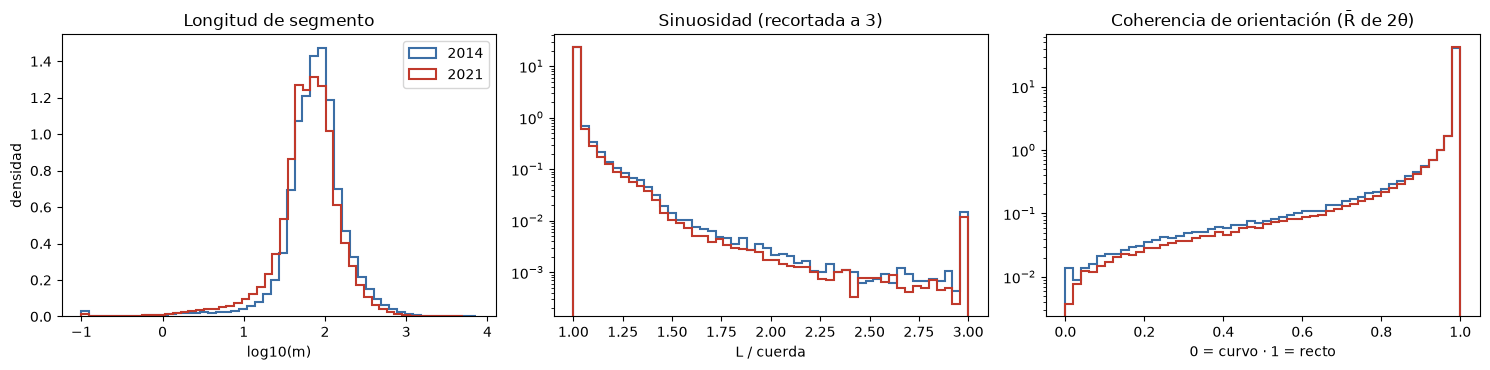

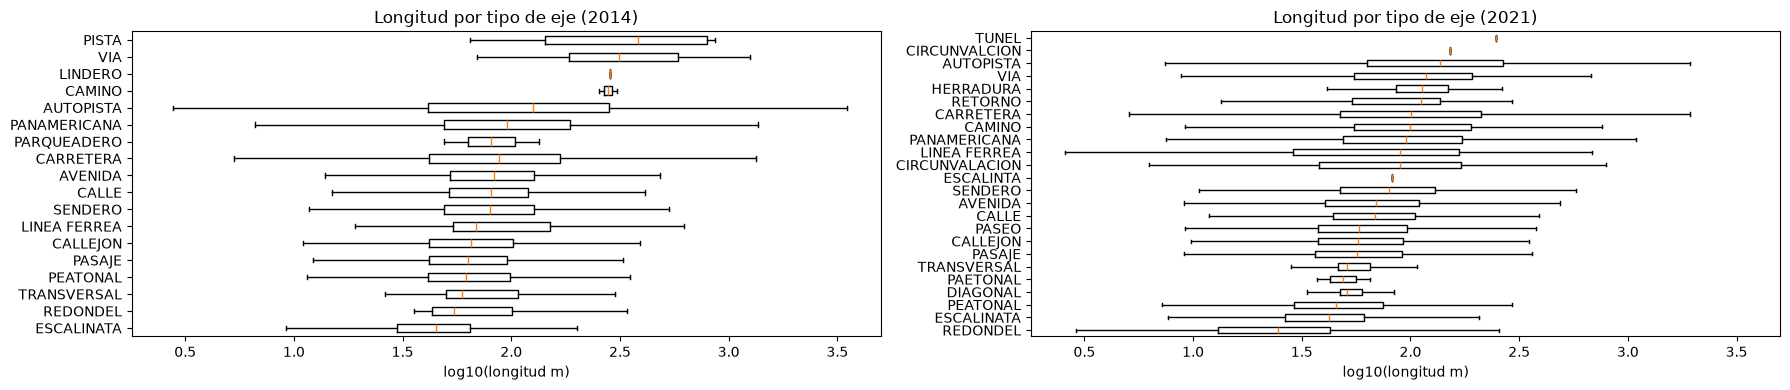

In [16]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for v, s in ejes.items():
    kw = dict(bins=50, density=True, histtype="step", linewidth=1.5, color=COLORES[v], label=str(ANIOS[v]))
    axs[0].hist(np.log10(s.eda_long_m.clip(lower=0.1)), **kw)
    axs[1].hist(s.eda_sinuos.clip(upper=3).dropna(), **kw)
    axs[2].hist(s.eda_coher, **kw)
axs[0].set(title="Longitud de segmento", xlabel="log10(m)", ylabel="densidad")
axs[1].set(title="Sinuosidad (recortada a 3)", xlabel="L / cuerda", yscale="log")
axs[2].set(title="Coherencia de orientación (R̄ de 2θ)", xlabel="0 = curvo · 1 = recto", yscale="log")
axs[0].legend()
plt.tight_layout(); plt.show()

con_tipo = {v: s for v, s in ejes.items() if "tipo_eje" in s.columns}
if con_tipo:
    fig, axs = plt.subplots(1, len(con_tipo), figsize=(9 * len(con_tipo), 4), sharex=True, squeeze=False)
    for ax, (v, s) in zip(axs[0], con_tipo.items()):
        orden = s.groupby("tipo_eje").eda_long_m.median().sort_values().index
        datos_bp = [np.log10(s.loc[s.tipo_eje == t, "eda_long_m"]) for t in orden]
        try:
            ax.boxplot(datos_bp, orientation="horizontal", showfliers=False)   # matplotlib >= 3.10
        except TypeError:
            ax.boxplot(datos_bp, vert=False, showfliers=False)
        ax.set_yticklabels(orden); ax.set(xlabel="log10(longitud m)", title=f"Longitud por tipo de eje ({ANIOS[v]})")
    plt.tight_layout(); plt.show()

### 7.1. Orientación de la red (forma)
- **Rosa de orientaciones** con rumbos recíprocos en 36 bins de 10° desplazados −5°, ponderada por longitud (Boeing, 2019).
- **Entropía de orientación** $H_o = -\sum_i P(o_i)\ln P(o_i)$ y **orden** $\varphi = 1 - \left(\frac{H_o - H_g}{H_{max} - H_g}\right)^2$ con $H_{max}=\ln 36$ y $H_g=\ln 4$ (cuadrícula perfecta): φ ≈ 1 cuadrícula, φ ≈ 0 desorden.
- **Componente N–S/E–O** $\bar C = \sum l_i\cos 2\theta_i / \sum l_i$: +1 si toda la longitud es N–S, −1 si es E–O. Es el término cos 2θ del tensor de orientación; responde directamente "¿predominan las calles N–S o E–O?". Una cuadrícula alineada a N–S/E–O da $\bar C \approx 0$, porque sus dos familias de calles se compensan: $\bar C$ mide el **desbalance** entre ellas; la alineación de la cuadrícula se lee en la rosa y en φ.

Se comparan tres variantes: rumbo de la **cuerda** (comparable con Boeing/OSMnx), de los **sub-tramos** (captura curvas) y sin ponderar. A escala nacional las orientaciones de ciudades distintas se anulan; la lectura por área está en la sección 7.3 y el ejemplo de una ciudad en 7.2.1.

H_o (nats)   φ orden   az_medio         R  \
versión variante                                                              
antigua Cuerda, por longitud        3.570069  0.012205  20.866055  0.011937   
        Sub-tramos, por longitud    3.568441  0.013677  20.155746  0.011538   
        Cuerda, sin ponderar        3.568694  0.013449  29.964211  0.004528   
actual  Cuerda, por longitud        3.570051  0.012221  26.533061  0.012092   
        Sub-tramos, por longitud    3.568610  0.013525  26.678730  0.011691   
        Cuerda, sin ponderar        3.569292  0.012908  31.530587  0.006026   

                                  comp_NS_EO  comp_NE_NO  
versión variante                                          
antigua Cuerda, por longitud        0.008908    0.007946  
        Sub-tramos, por longitud    0.008798    0.007465  
        Cuerda, sin ponderar        0.002269    0.003919  
actual  Cuerda, por longitud        0.007266    0.009666  
        Sub-tramos, por longitud    0.006977    0.009381  
        Cuerda, sin ponderar        0.002730    0.005372

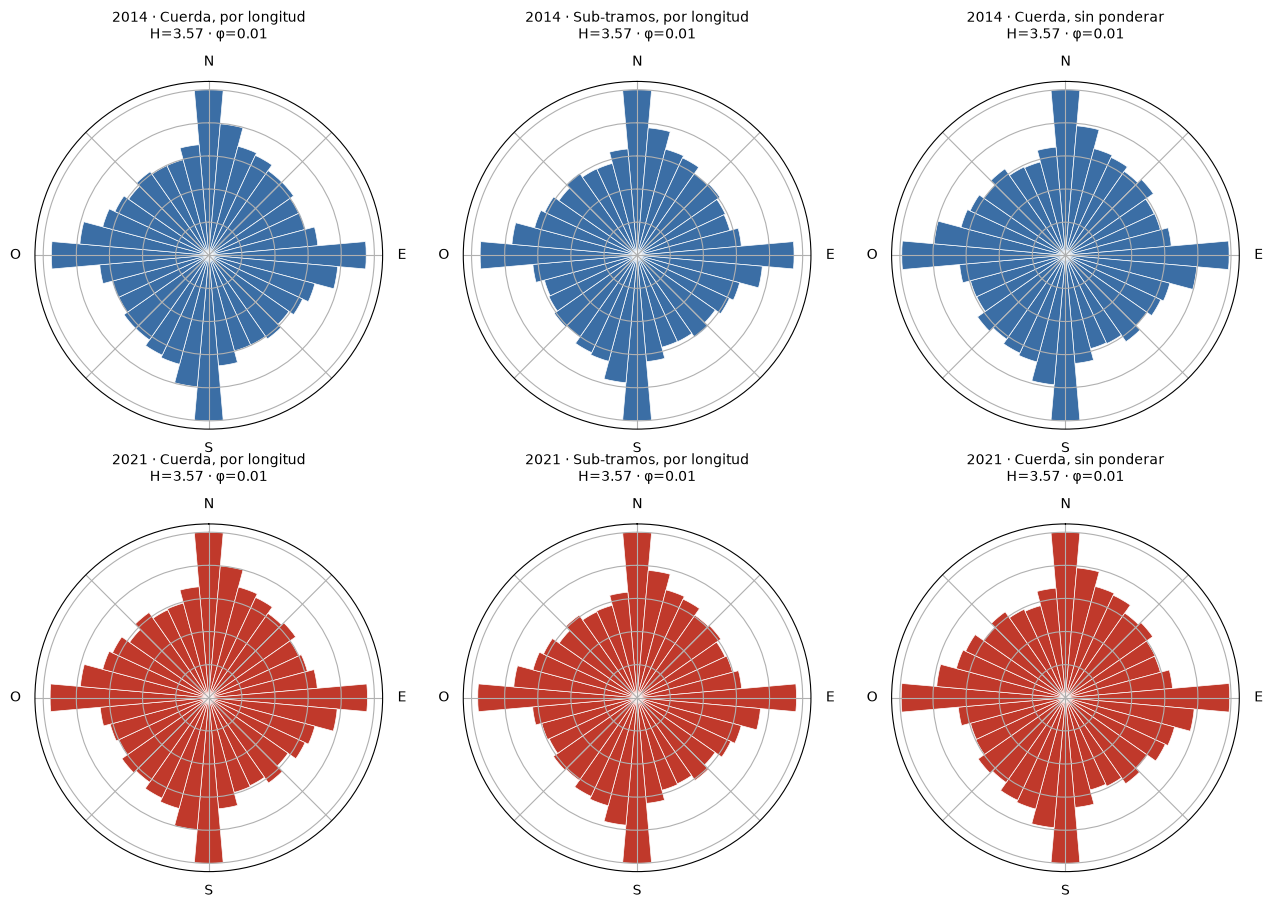

In [17]:
filas = []
fig, axs = plt.subplots(len(ejes), 3, figsize=(13, 4.5 * len(ejes)), subplot_kw={"projection": "polar"}, squeeze=False)
for fila, (v, s) in zip(axs, ejes.items()):
    sl, th, *_ = subsegmentos(s.geometry.values)
    variantes = {
        "Cuerda, por longitud": (s.eda_az_cuerda, s.eda_long_m),
        "Sub-tramos, por longitud": (np.degrees(th) % 180, sl),
        "Cuerda, sin ponderar": (s.eda_az_cuerda, None),
    }
    for ax, (k, (a, w)) in zip(fila, variantes.items()):
        H, phi = entropia_orientacion(a, w)
        filas.append({"versión": v, "variante": k, "H_o (nats)": H, "φ orden": phi, **resumen_axial(a, w)})
        rosa(ax, a, w, titulo=f"{ANIOS[v]} · {k}\nH={H:.2f} · φ={phi:.2f}", color=COLORES[v])
tabla_or = pd.DataFrame(filas).set_index(["versión", "variante"])
display(tabla_or)
plt.tight_layout(); plt.show()

In [18]:
# Participación de longitud por clase de orientación
part = pd.DataFrame({v: s.groupby("eda_clase_or", observed=False).eda_long_m.sum() for v, s in ejes.items()})
part = part / part.sum()
anisotropia = (part.loc["N–S"] - part.loc["E–O"]) / (part.loc["N–S"] + part.loc["E–O"])
print("Índice de anisotropía (L_NS − L_EO)/(L_NS + L_EO):", anisotropia.round(3).to_dict())
part

Índice de anisotropía (L_NS − L_EO)/(L_NS + L_EO): {'antigua': 0.014, 'actual': 0.013}


,antigua,actual
eda_clase_or,,
N–S,0.278797,0.278059
NE–SO,0.229024,0.229699
E–O,0.270880,0.271038
NO–SE,0.221300,0.221204


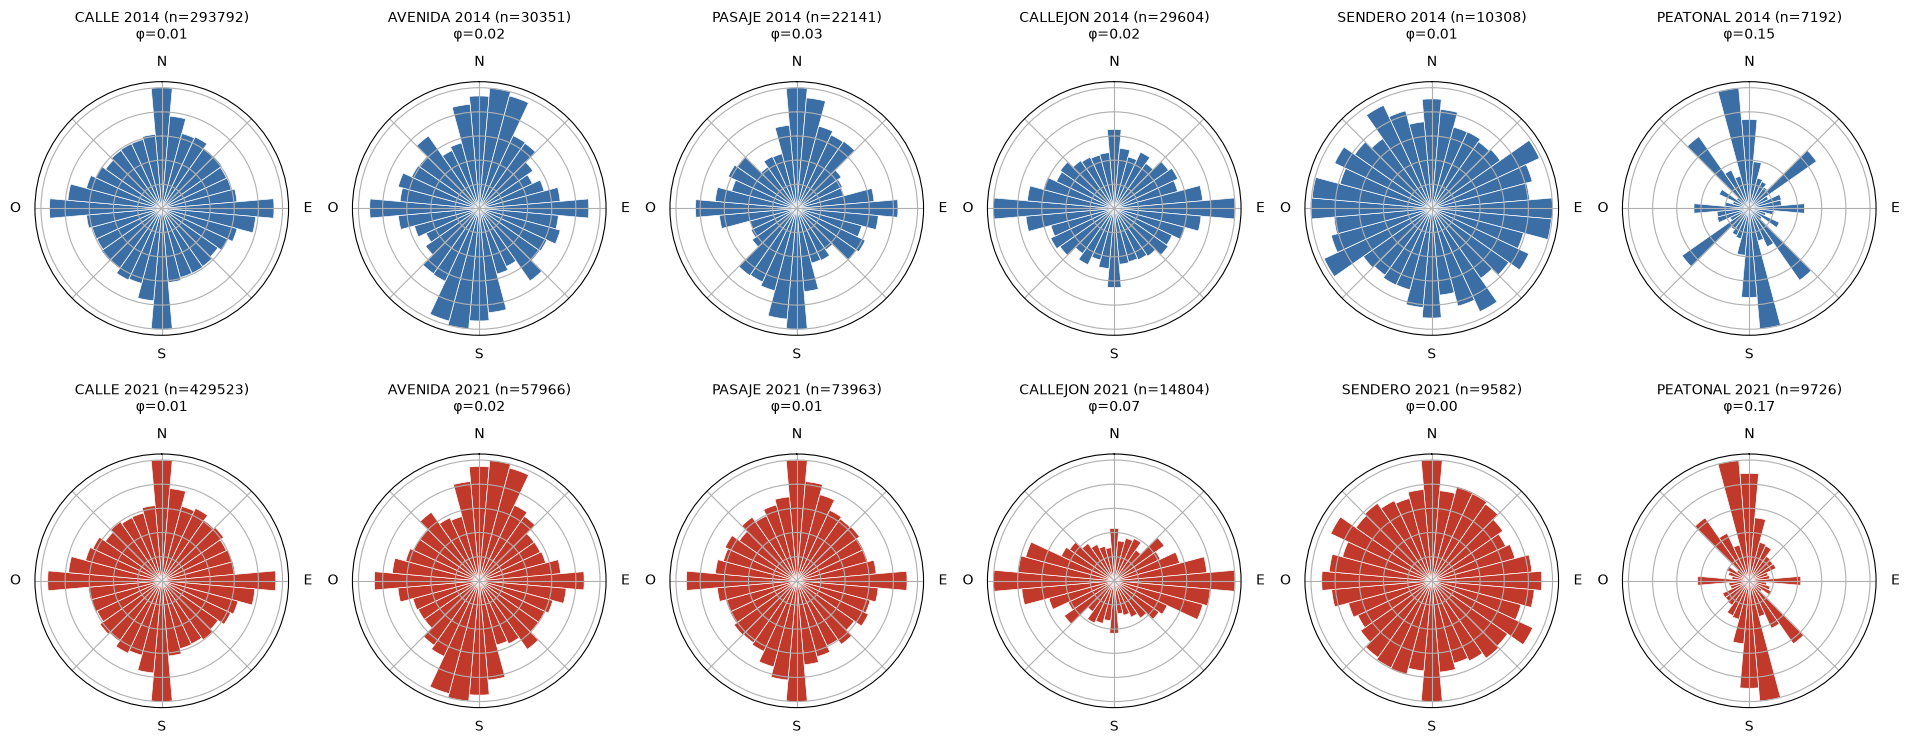

In [19]:
tipos = [t for t in ejes["actual"].groupby("tipo_eje").eda_long_m.sum().sort_values(ascending=False).index[:6]]
fig, axs = plt.subplots(len(ejes), len(tipos), figsize=(3.2 * len(tipos), 3.8 * len(ejes)),
                        subplot_kw={"projection": "polar"}, squeeze=False)
for fila, (v, s) in zip(axs, ejes.items()):
    for ax, t in zip(fila, tipos):
        st = s[s.tipo_eje == t] if "tipo_eje" in s.columns else s.iloc[:0]
        if st.eda_az_cuerda.notna().sum() == 0:
            ax.set_axis_off(); continue
        H, phi = entropia_orientacion(st.eda_az_cuerda, st.eda_long_m)
        rosa(ax, st.eda_az_cuerda, st.eda_long_m, titulo=f"{t} {ANIOS[v]} (n={len(st)})\nφ={phi:.2f}", color=COLORES[v])
plt.tight_layout(); plt.show()

### 7.2. Mapas
Densidad vial y orientación dominante por celda de `TAM_CELDA` m, con la misma escala de color para las dos versiones.

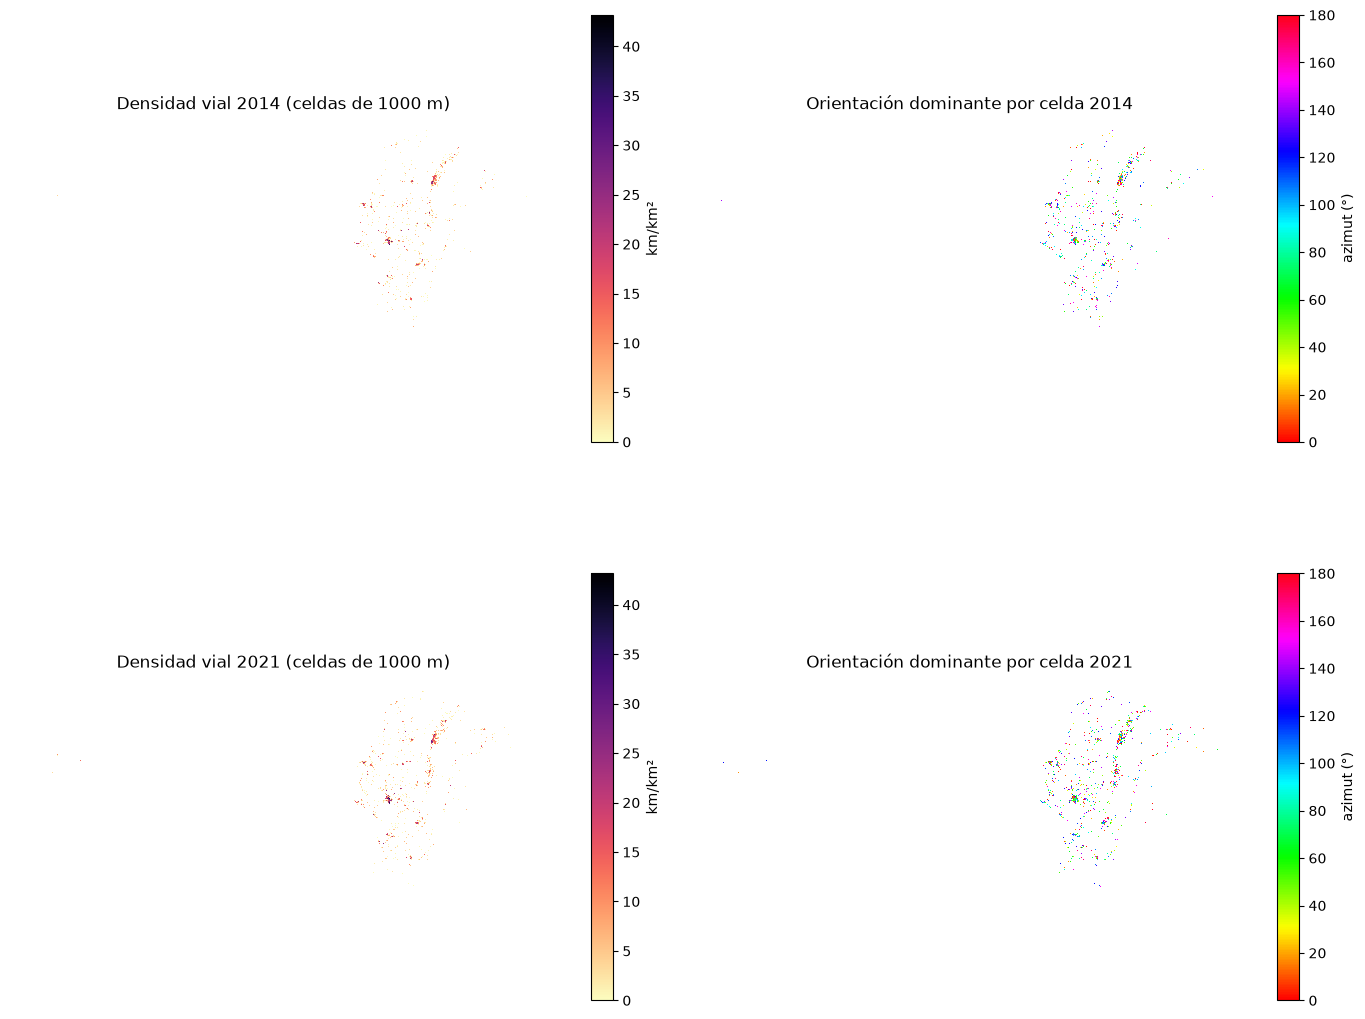

In [20]:
grilla = {}
for v, s in ejes.items():
    ix = np.floor(s.eda_cx / TAM_CELDA).astype(np.int64)
    iy = np.floor(s.eda_cy / TAM_CELDA).astype(np.int64)
    celdas = (pd.DataFrame({"ix": ix, "iy": iy, "L": s.eda_long_m, "c2": s._c2, "s2": s._s2})
              .groupby(["ix", "iy"]).sum().reset_index())
    celdas["dens_km_km2"] = (celdas.L / 1000) / (TAM_CELDA / 1000) ** 2
    celdas["az_dom"] = (np.degrees(np.arctan2(celdas.s2, celdas.c2)) / 2) % 180
    grilla[v] = gpd.GeoDataFrame(celdas, crs=s.crs, geometry=shapely.box(
        celdas.ix * TAM_CELDA, celdas.iy * TAM_CELDA, (celdas.ix + 1) * TAM_CELDA, (celdas.iy + 1) * TAM_CELDA))

vmax = max(g.dens_km_km2.max() for g in grilla.values())
fig, axs = plt.subplots(len(grilla), 2, figsize=(14, 6.5 * len(grilla)), squeeze=False)
for (ax1, ax2), (v, g) in zip(axs, grilla.items()):
    g.plot("dens_km_km2", ax=ax1, cmap="magma_r", vmin=0, vmax=vmax, legend=True,
           legend_kwds={"shrink": .6, "label": "km/km²"})
    ax1.set_title(f"Densidad vial {ANIOS[v]} (celdas de {TAM_CELDA} m)")
    g.plot("az_dom", ax=ax2, cmap=CMAP_AXIAL, vmin=0, vmax=180, legend=True,
           legend_kwds={"shrink": .6, "label": "azimut (°)"})
    ax2.set_title(f"Orientación dominante por celda {ANIOS[v]}")
    ax1.set_axis_off(); ax2.set_axis_off()
plt.tight_layout(); plt.show()

#### 7.2.1. Ejemplo: gráficas de 7.1 y mapas de 7.2 en un subconjunto
A escala nacional las rosas son casi isotrópicas (las orientaciones de ciudades distintas se anulan) y los mapas de celdas de 1 km apenas se leen. Esta celda repite las **rosas de 7.1** y los **mapas de 7.2** solo para el subconjunto de `FILTRO_EJEMPLO` (sección 1): un área, varias áreas o una provincia. Las secciones 7.1 y 7.2 no cambian.

- Los mapas usan celdas de `TAM_CELDA_EJ` m y la misma extensión en las dos versiones, para compararlas directamente.
- Las variables de esta celda llevan el sufijo `_ej`, así que no sobrescriben las de 7.1–7.2.

Filtro: area en ['GUAYAQUIL | 090150']
  antigua (2014): 44,937 segmentos | 4,647.5 km
  actual (2021): 58,594 segmentos | 5,061.1 km


H_o (nats)  φ orden  az_medio      R  \
versión variante                                                         
antigua Cuerda, por longitud           3.529    0.049    11.608  0.019   
        Sub-tramos, por longitud       3.529    0.049    13.858  0.017   
        Cuerda, sin ponderar           3.521    0.056     8.718  0.004   
actual  Cuerda, por longitud           3.533    0.046    16.351  0.019   
        Sub-tramos, por longitud       3.536    0.043    16.544  0.018   
        Cuerda, sin ponderar           3.518    0.059    22.323  0.014   

                                  comp_NS_EO  comp_NE_NO  
versión variante                                          
antigua Cuerda, por longitud           0.018       0.008  
        Sub-tramos, por longitud       0.015       0.008  
        Cuerda, sin ponderar           0.004       0.001  
actual  Cuerda, por longitud           0.016       0.010  
        Sub-tramos, por longitud       0.015       0.010  
        Cuerda, sin ponderar           0.010       0.010

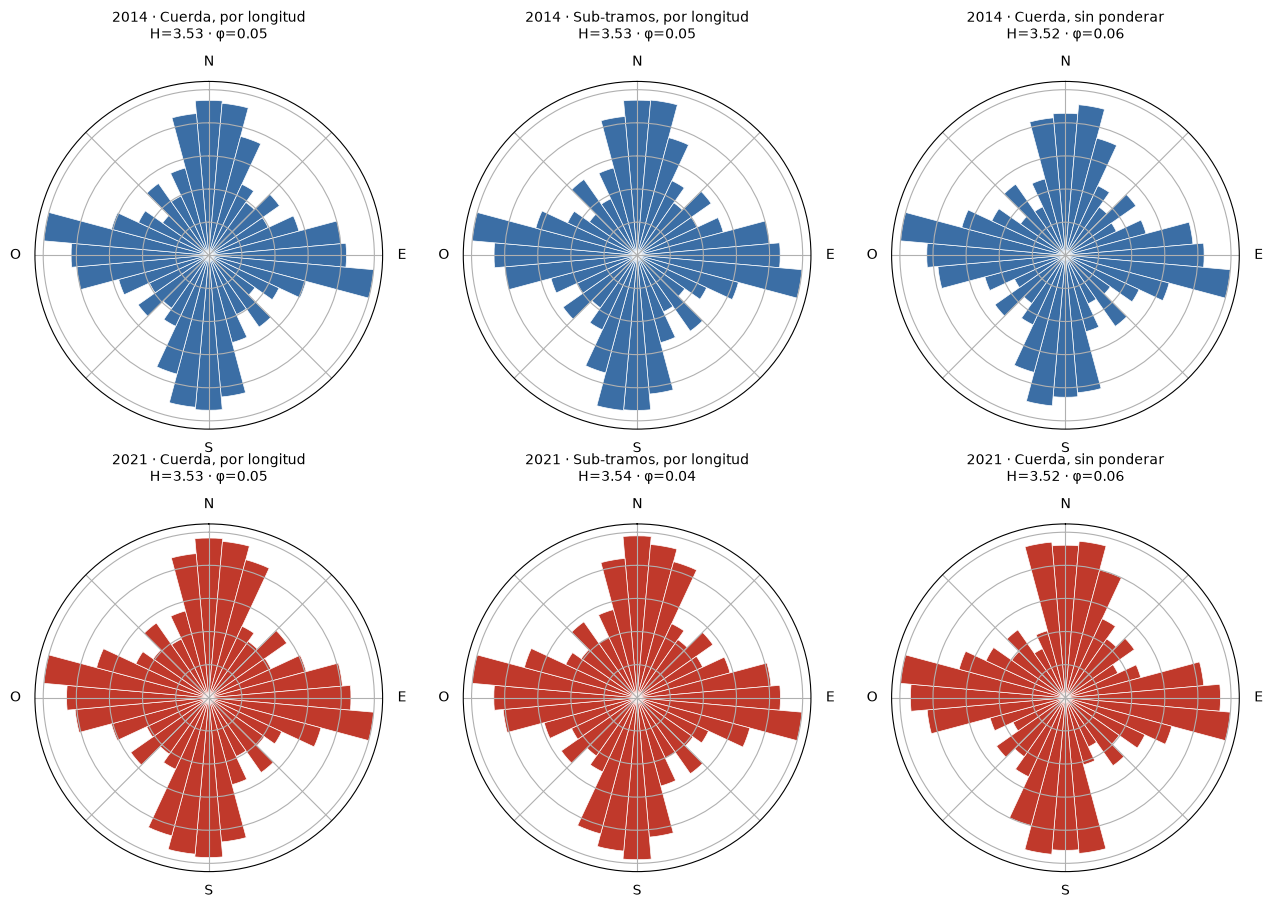

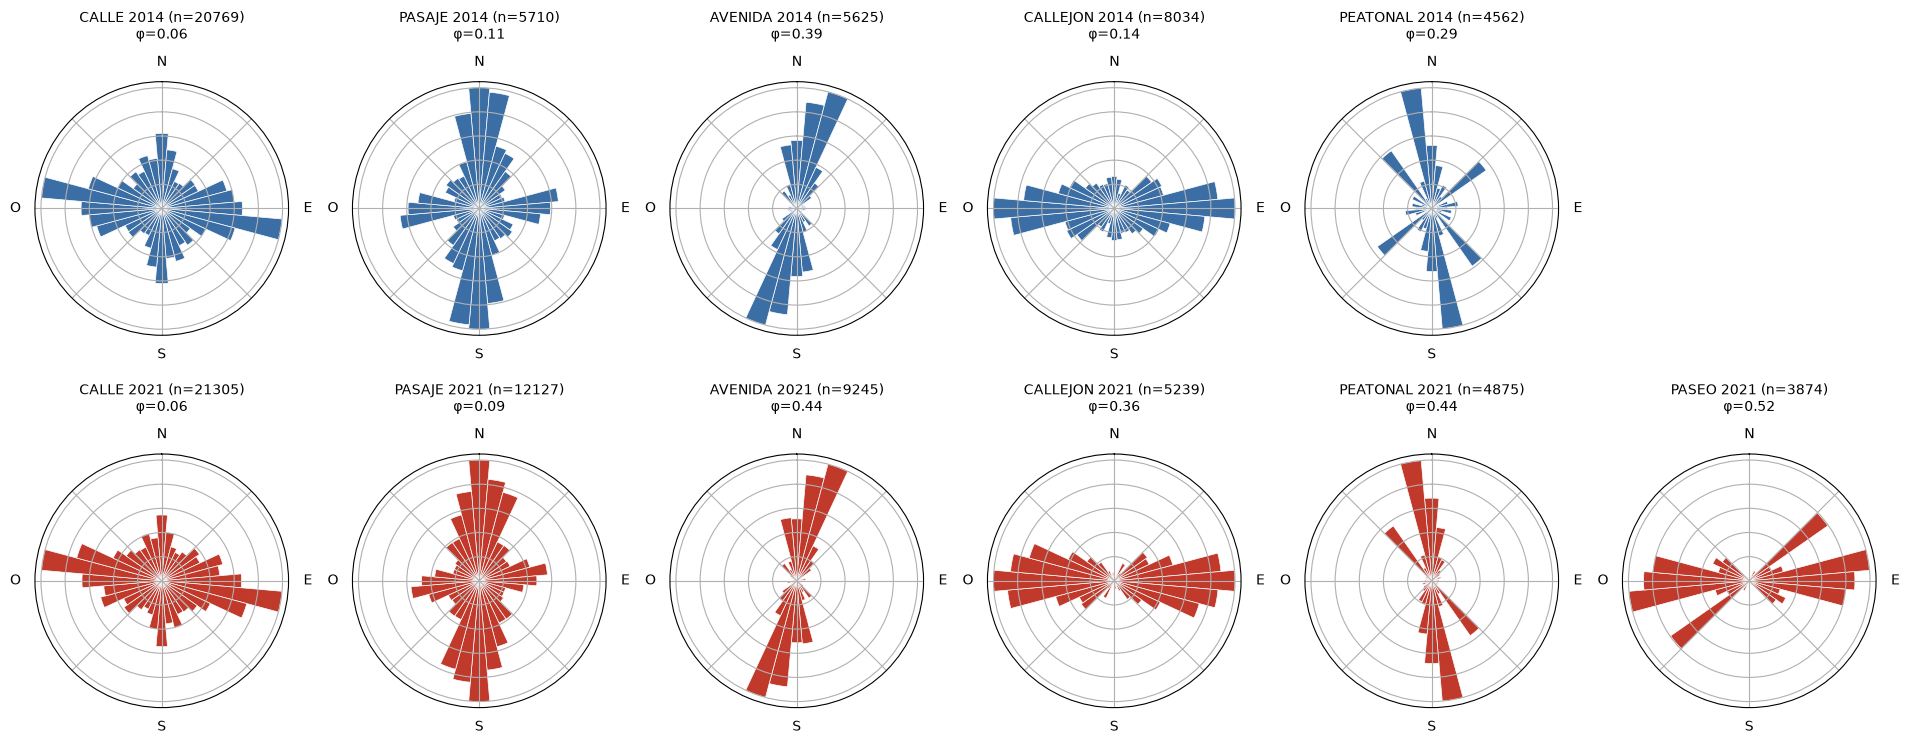

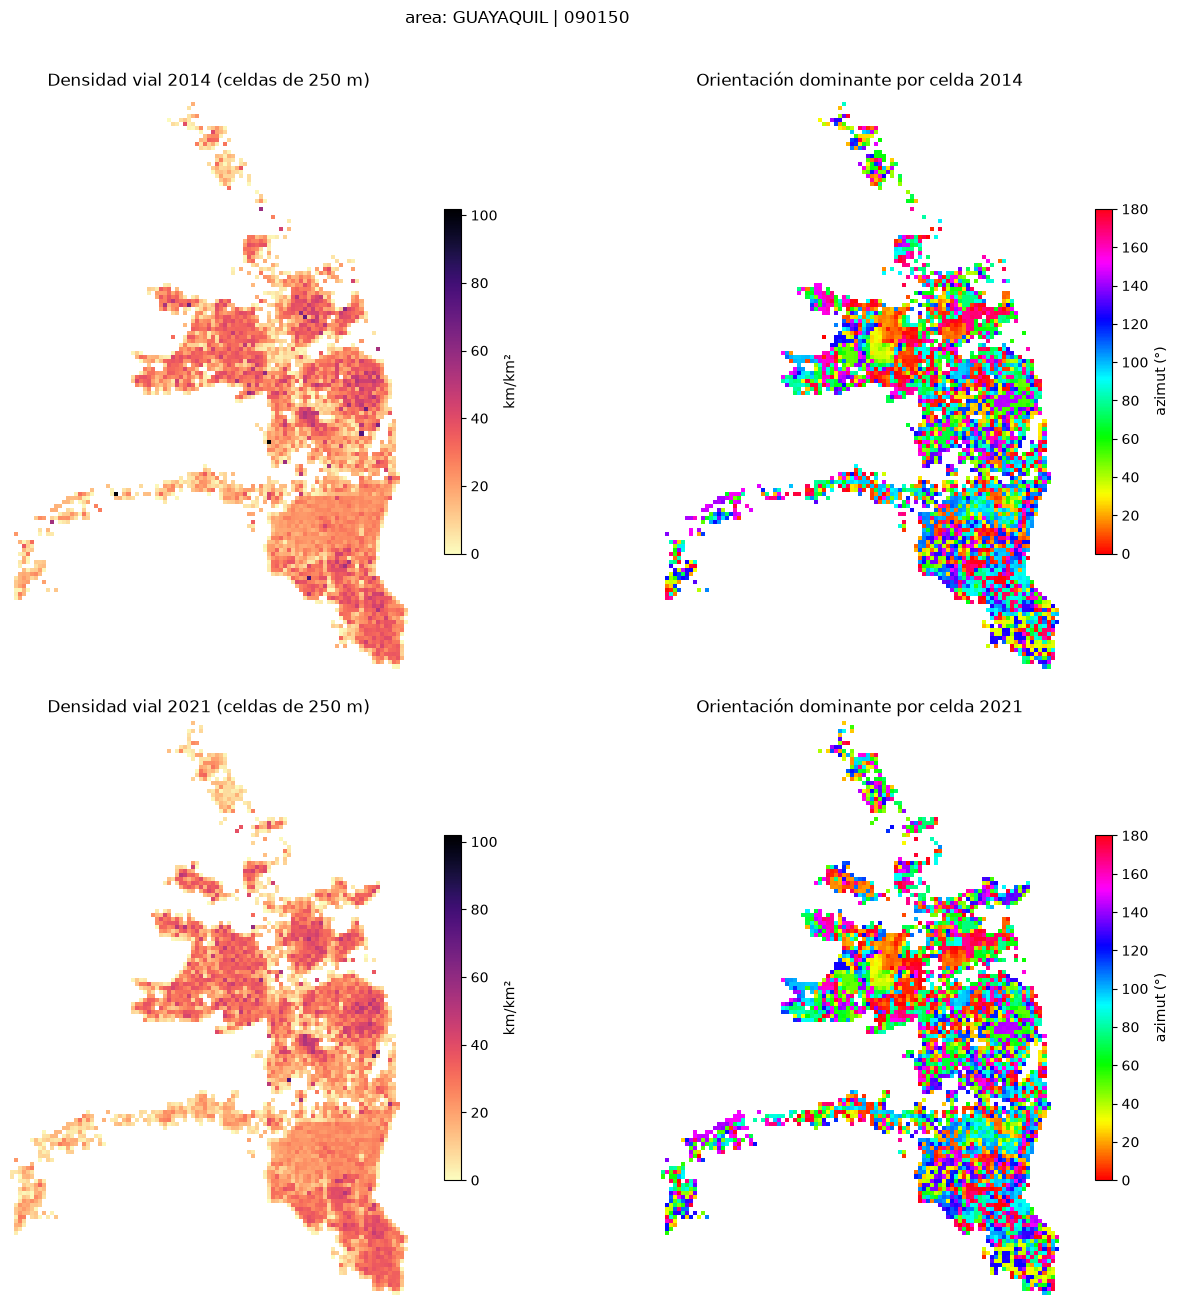

In [21]:
# Ejemplo: gráficas de 7.1 y mapas de 7.2 solo para el subconjunto de FILTRO_EJEMPLO
campo_ej, valores_ej = FILTRO_EJEMPLO or (CAMPO_GRUPO, [AREA_EJEMPLO or ejes["actual"].groupby(CAMPO_GRUPO).eda_long_m.sum().idxmax()])
ej = {v: s[s[campo_ej].isin(valores_ej)] for v, s in ejes.items() if campo_ej in s.columns}
ej = {v: s for v, s in ej.items() if len(s)}   # versiones sin segmentos en el filtro no se grafican
print(f"Filtro: {campo_ej} en {valores_ej}")
for v, s in ej.items():
    print(f"  {v} ({ANIOS[v]}): {len(s):,} segmentos | {s.eda_long_m.sum() / 1000:,.1f} km")

# Rosas de orientación: las tres variantes de 7.1
filas_ej = []
fig, axs = plt.subplots(len(ej), 3, figsize=(13, 4.5 * len(ej)), subplot_kw={"projection": "polar"}, squeeze=False)
for fila, (v, s) in zip(axs, ej.items()):
    sl, th, *_ = subsegmentos(s.geometry.values)
    variantes = {
        "Cuerda, por longitud": (s.eda_az_cuerda, s.eda_long_m),
        "Sub-tramos, por longitud": (np.degrees(th) % 180, sl),
        "Cuerda, sin ponderar": (s.eda_az_cuerda, None),
    }
    for ax, (k, (a, w)) in zip(fila, variantes.items()):
        H, phi = entropia_orientacion(a, w)
        filas_ej.append({"versión": v, "variante": k, "H_o (nats)": H, "φ orden": phi, **resumen_axial(a, w)})
        rosa(ax, a, w, titulo=f"{ANIOS[v]} · {k}\nH={H:.2f} · φ={phi:.2f}", color=COLORES[v])
display(pd.DataFrame(filas_ej).set_index(["versión", "variante"]).round(3))
plt.tight_layout(); plt.show()

# Rosas por tipo de eje (los 6 tipos con más longitud en el subconjunto)
s_ref = ej.get("actual", next(iter(ej.values())))
tipos_ej = s_ref.groupby("tipo_eje").eda_long_m.sum().sort_values(ascending=False).index[:6]
fig, axs = plt.subplots(len(ej), len(tipos_ej), figsize=(3.2 * len(tipos_ej), 3.8 * len(ej)),
                        subplot_kw={"projection": "polar"}, squeeze=False)
for fila, (v, s) in zip(axs, ej.items()):
    for ax, t in zip(fila, tipos_ej):
        st = s[s.tipo_eje == t]
        if st.eda_az_cuerda.notna().sum() == 0:
            ax.set_axis_off(); continue
        H, phi = entropia_orientacion(st.eda_az_cuerda, st.eda_long_m)
        rosa(ax, st.eda_az_cuerda, st.eda_long_m, titulo=f"{t} {ANIOS[v]} (n={len(st)})\nφ={phi:.2f}", color=COLORES[v])
plt.tight_layout(); plt.show()

# Mapas: densidad vial y orientación dominante por celda de TAM_CELDA_EJ m
grilla_ej = {}
for v, s in ej.items():
    ix = np.floor(s.eda_cx / TAM_CELDA_EJ).astype(np.int64)
    iy = np.floor(s.eda_cy / TAM_CELDA_EJ).astype(np.int64)
    celdas = (pd.DataFrame({"ix": ix, "iy": iy, "L": s.eda_long_m, "c2": s._c2, "s2": s._s2})
              .groupby(["ix", "iy"]).sum().reset_index())
    celdas["dens_km_km2"] = (celdas.L / 1000) / (TAM_CELDA_EJ / 1000) ** 2
    celdas["az_dom"] = (np.degrees(np.arctan2(celdas.s2, celdas.c2)) / 2) % 180
    grilla_ej[v] = gpd.GeoDataFrame(celdas, crs=s.crs, geometry=shapely.box(
        celdas.ix * TAM_CELDA_EJ, celdas.iy * TAM_CELDA_EJ, (celdas.ix + 1) * TAM_CELDA_EJ, (celdas.iy + 1) * TAM_CELDA_EJ))

vmax_ej = max(g.dens_km_km2.max() for g in grilla_ej.values())
caja = np.array([g.total_bounds for g in grilla_ej.values()])   # misma extensión para las dos versiones
fig, axs = plt.subplots(len(grilla_ej), 2, figsize=(14, 6.5 * len(grilla_ej)), squeeze=False)
for (ax1, ax2), (v, g) in zip(axs, grilla_ej.items()):
    g.plot("dens_km_km2", ax=ax1, cmap="magma_r", vmin=0, vmax=vmax_ej, legend=True,
           legend_kwds={"shrink": .6, "label": "km/km²"})
    ax1.set_title(f"Densidad vial {ANIOS[v]} (celdas de {TAM_CELDA_EJ} m)")
    g.plot("az_dom", ax=ax2, cmap=CMAP_AXIAL, vmin=0, vmax=180, legend=True,
           legend_kwds={"shrink": .6, "label": "azimut (°)"})
    ax2.set_title(f"Orientación dominante por celda {ANIOS[v]}")
    for ax in (ax1, ax2):
        ax.set_xlim(caja[:, 0].min(), caja[:, 2].max()); ax.set_ylim(caja[:, 1].min(), caja[:, 3].max())
        ax.set_axis_off()
fig.suptitle(f"{campo_ej}: {', '.join(map(str, valores_ej))}", y=1.0)
plt.tight_layout(); plt.show()

### 7.3. Resumen por área y versión
`metricas_grupo` (sección 5) por `CAMPO_GRUPO` y versión, solo para grupos con al menos `MIN_SEGMENTOS` segmentos en esa versión. La tabla `comp` une las dos versiones con sufijos `_14` y `_21`: es la base de las secciones 8 a 10.

In [22]:
por_grupo = {}
for v, s in ejes.items():
    s = s[s[CAMPO_GRUPO].notna()]
    s = s[s.groupby(CAMPO_GRUPO)[CAMPO_GRUPO].transform("size") >= MIN_SEGMENTOS]
    por_grupo[v] = s.groupby(CAMPO_GRUPO).apply(metricas_grupo, include_groups=False)

comp = por_grupo["antigua"].add_suffix("_14").join(por_grupo["actual"].add_suffix("_21"), how="outer")

print(f"Grupos ({CAMPO_GRUPO}) con las dos versiones: {comp[['long_km_14', 'long_km_21']].notna().all(axis=1).sum()} | "
      f"solo actual (nuevos): {comp.long_km_14.isna().sum()} | solo antigua: {comp.long_km_21.isna().sum()}")
print("\nMedianas por versión:")
display(pd.DataFrame({v: p[["long_km", "phi", "R", "C_NS_EO", "sinuos_mediana", "elongacion"]].median()
                      for v, p in por_grupo.items()}).round(3))
cols_ver = ["long_km_14", "long_km_21", "phi_14", "phi_21", "C_NS_EO_14", "C_NS_EO_21",
            "az_elipse_14", "az_elipse_21", "elongacion_14", "elongacion_21"]
comp[cols_ver].sort_values("long_km_21", ascending=False).head(20).round(3)

Grupos (area) con las dos versiones: 763 | solo actual (nuevos): 378 | solo antigua: 45

Medianas por versión:


,antigua,actual
long_km,12.252,10.973
phi,0.444,0.425
R,0.118,0.118
C_NS_EO,0.006,0.003
sinuos_mediana,1.000,1.000
elongacion,1.819,1.865


,long_km_14,long_km_21,phi_14,phi_21,C_NS_EO_14,C_NS_EO_21,az_elipse_14,az_elipse_21,elongacion_14,elongacion_21
area,,,,,,,,,,
GUAYAQUIL | 090150,4647.541,5061.091,0.049,0.046,0.018,0.016,160.047,160.645,1.800,1.743
QUITO | 170150,3824.470,4196.202,0.038,0.039,0.060,0.074,18.434,18.444,4.220,4.219
CUENCA | 010150,1151.665,1266.257,0.008,0.008,-0.037,-0.034,69.817,69.851,2.241,2.224
SANTO DOMINGO DE LOS COLORADOS | 230150,975.763,1106.633,0.198,0.166,0.000,0.001,66.027,65.504,1.392,1.267
MANTA | 130850,781.257,922.059,0.042,0.038,0.023,0.015,93.560,92.621,1.940,1.974
PORTOVIEJO | 130150,737.763,912.414,0.049,0.032,-0.009,-0.008,140.505,144.012,2.244,1.990
DURÁN | 090750,739.301,832.191,0.140,0.153,-0.007,0.002,76.326,70.624,1.188,1.072
LOJA | 110150,734.008,831.113,0.069,0.058,0.067,0.080,166.828,167.744,2.009,2.025
MACHALA | 070150,724.892,797.230,0.166,0.155,-0.028,-0.024,110.358,112.463,1.928,1.912


## 8. Extensión espacial: área de ejemplo
Responde *¿hacia dónde se alarga la mancha vial?*, que es independiente de hacia dónde apuntan las calles. Se trabaja sobre un área (`AREA_EJEMPLO`): a escala de provincia o país la elipse mezclaría varias ciudades.

- **Elipse de desviación estándar** de cada versión (valores de la sección 7.3) y % de la longitud que queda dentro.
- **Anillos y sectores** desde un centro **común a las dos fechas** (`CENTRO_EXT`; por defecto, el centro medio ponderado 2014): longitud vial por anillo de `ANCHO_ANILLO` m y por sector, y **alcance P95** por sector: distancia que contiene el 95 % de la longitud vial de ese sector.
- **Índice de alargamiento** $(A_{NS} - A_{EO}) / (A_{NS} + A_{EO})$, con $A$ = alcance P95 medio de los sectores opuestos: + se extiende N–S, − se extiende E–O.

In [23]:
area_m = AREA_EJEMPLO or comp.loc[comp.long_km_14.notna(), "long_km_21"].idxmax()
versiones_m = [v for v in ANIOS if area_m in por_grupo[v].index]
r14 = por_grupo["antigua"].loc[area_m]
cx, cy = CENTRO_EXT or (r14.xm, r14.ym)                          # mismo centro para las dos fechas
ancho_s = 360 / N_SECTORES
centros_s = np.arange(N_SECTORES) * ancho_s
nombres_s = (["N", "NE", "E", "SE", "S", "SO", "O", "NO"] if N_SECTORES == 8
             else [f"{c:.0f}°" for c in centros_s])
t = np.linspace(0, 2 * np.pi, 200)

filas, elipses, por_sector, km_as = {}, {}, {}, {}
for v in versiones_m:
    e = ejes[v][ejes[v][CAMPO_GRUPO] == area_m]
    r = por_grupo[v].loc[area_m]
    w = e.eda_long_m.to_numpy()
    x, y = e.eda_cx.to_numpy(), e.eda_cy.to_numpy()

    # Elipse (parámetros de la sección 7.3)
    az = np.radians(r.az_elipse)
    u, n_ = np.array([np.sin(az), np.cos(az)]), np.array([np.cos(az), -np.sin(az)])   # eje mayor y menor
    elipses[v] = shapely.Polygon(np.array([r.xm, r.ym]) + np.outer(np.cos(t), u) * r.elip_a_km * 1000
                                 + np.outer(np.sin(t), n_) * r.elip_b_km * 1000)
    dentro = shapely.contains_xy(elipses[v], x, y)

    # Anillos y sectores desde el centro común
    dx, dy = x - cx, y - cy
    dist = np.hypot(dx, dy)
    sector = (((np.degrees(np.arctan2(dx, dy)) % 360) + ancho_s / 2) % 360 // ancho_s).astype(int)
    df_as = pd.DataFrame({"sector": sector, "anillo": (dist // ANCHO_ANILLO).astype(int), "dist": dist, "L": w})
    km_as[v] = (df_as.pivot_table(index="anillo", columns="sector", values="L", aggfunc="sum", fill_value=0)
                .reindex(columns=range(N_SECTORES), fill_value=0) / 1000)
    df_as = df_as.sort_values("dist")
    df_as["frac"] = df_as.groupby("sector").L.cumsum() / df_as.groupby("sector").L.transform("sum")
    alcance = df_as[df_as.frac >= 0.95].groupby("sector").dist.min().reindex(range(N_SECTORES)) / 1000
    ps = pd.DataFrame({"sector": nombres_s, "az_centro": centros_s, "long_km": km_as[v].sum().values,
                       "alcance_p95_km": alcance.values, "clase": clase_orientacion(centros_s % 180)})
    por_sector[v] = ps.set_index("sector")
    A_ns = ps.loc[ps.clase == "N–S", "alcance_p95_km"].mean()
    A_eo = ps.loc[ps.clase == "E–O", "alcance_p95_km"].mean()

    filas[ANIOS[v]] = {
        "Segmentos": len(e), "Longitud (km)": round(w.sum() / 1000, 1),
        "Centro elipse (x, y)": f"{r.xm:,.0f}, {r.ym:,.0f}",
        "Semieje mayor a (km)": round(r.elip_a_km, 2), "Semieje menor b (km)": round(r.elip_b_km, 2),
        "Elongación a/b": round(r.elongacion, 2), "Azimut eje mayor (°)": round(r.az_elipse, 1),
        "Clase del eje mayor": clase_orientacion([r.az_elipse])[0],
        "% longitud dentro de la elipse": round(100 * w[dentro].sum() / w.sum(), 1),
        "A_NS (km)": round(A_ns, 2), "A_EO (km)": round(A_eo, 2),
        "Índice de alargamiento": round((A_ns - A_eo) / (A_ns + A_eo), 3),
    }
tabla_ext = pd.DataFrame(filas)
print(f"Área: {area_m} | centro de anillos y sectores: {cx:,.0f}, {cy:,.0f}")
display(tabla_ext)
display(pd.concat({ANIOS[v]: p[["long_km", "alcance_p95_km"]] for v, p in por_sector.items()}, axis=1).round(2))

Área: GUAYAQUIL | 090150 | centro de anillos y sectores: 618,831, 9,761,549


,2014,2021
Segmentos,44937,58594
Longitud (km),4647.5,5061.1
"Centro elipse (x, y)","618,831, 9,761,549","618,468, 9,762,097"
Semieje mayor a (km),10.25,10.52
Semieje menor b (km),5.7,6.04
Elongación a/b,1.8,1.74
Azimut eje mayor (°),160.0,160.6
Clase del eje mayor,N–S,N–S
% longitud dentro de la elipse,68.4,69.1
A_NS (km),16.17,16.19


2014                    2021               
       long_km alcance_p95_km  long_km alcance_p95_km
sector                                               
N       866.12          18.57   967.14          18.65
NE      550.73           8.32   572.47           8.86
E       294.90           5.97   292.53           5.96
SE      771.29          14.20   772.82          14.21
S       882.93          13.77   898.23          13.73
SO      188.98          19.50   222.48          19.61
O       178.01          16.82   211.57          17.08
NO      914.58          11.31  1123.86          12.74

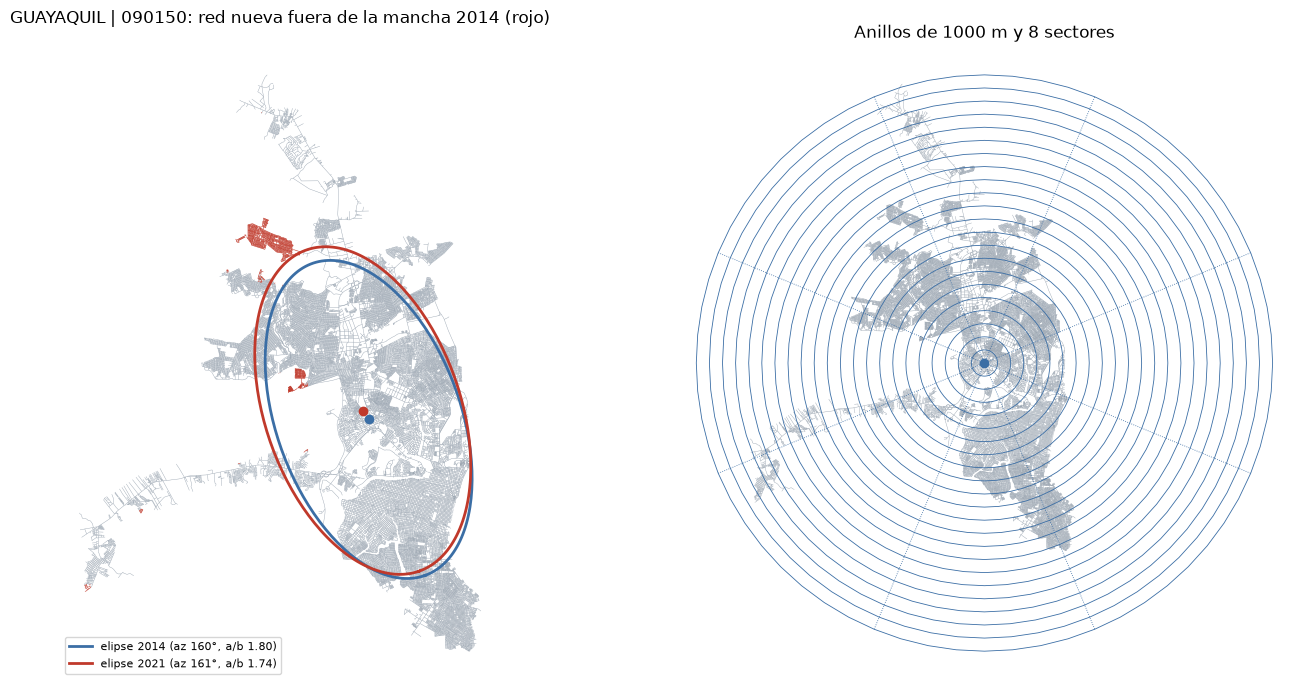

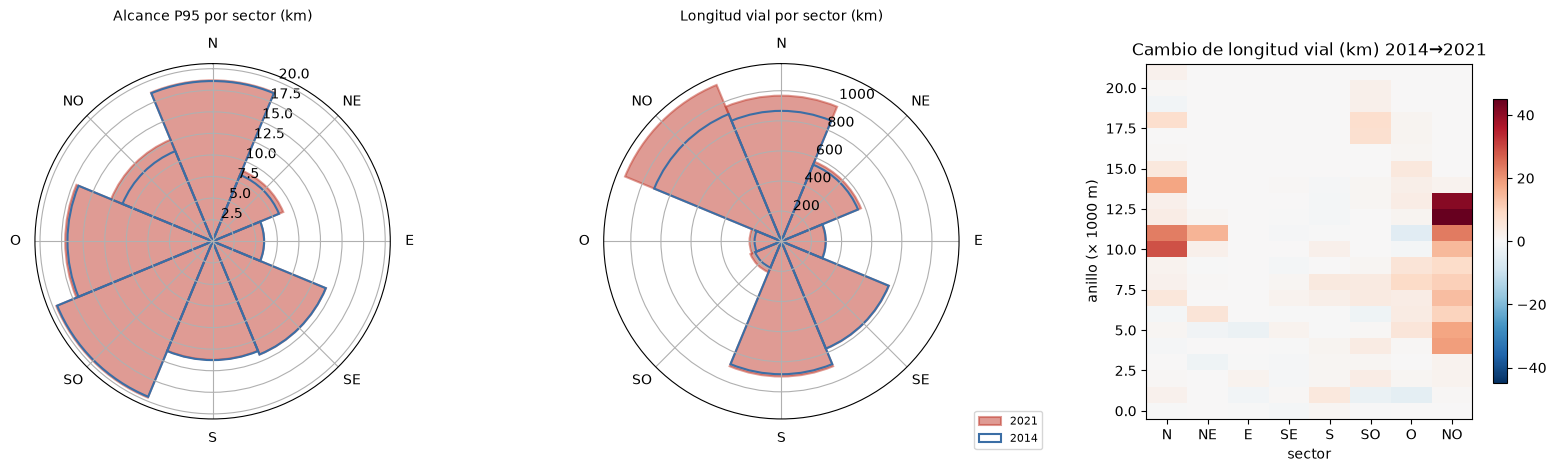

In [24]:
# Mapas: red nueva y elipses de las dos fechas; anillos y sectores sobre la red actual
e21 = ejes["actual"][ejes["actual"][CAMPO_GRUPO] == area_m]
dist21 = np.hypot(e21.eda_cx - cx, e21.eda_cy - cy)
r_max = ANCHO_ANILLO * (int(dist21.max() // ANCHO_ANILLO) + 1)
anillos = gpd.GeoSeries([shapely.Point(cx, cy).buffer(r).exterior
                         for r in range(ANCHO_ANILLO, r_max + 1, ANCHO_ANILLO)], crs=e21.crs)
bordes = np.radians(centros_s - ancho_s / 2)
rayos = gpd.GeoSeries(shapely.linestrings(np.stack([np.c_[np.full(N_SECTORES, cx), np.full(N_SECTORES, cy)],
                                                    np.c_[cx + r_max * np.sin(bordes), cy + r_max * np.cos(bordes)]], axis=1)),
                      crs=e21.crs)

fig, axs = plt.subplots(1, 2, figsize=(15, 7))
e21[e21["area_ant"].notna()].plot(ax=axs[0], color=COLOR_BASE, linewidth=0.3)
e21[e21["area_ant"].isna()].plot(ax=axs[0], color=COLORES["actual"], linewidth=0.4)
for v in versiones_m:
    r = por_grupo[v].loc[area_m]
    xe, ye = elipses[v].exterior.xy
    axs[0].plot(xe, ye, color=COLORES[v], linewidth=2,
                label=f"elipse {ANIOS[v]} (az {r.az_elipse:.0f}°, a/b {r.elongacion:.2f})")
    axs[0].plot(r.xm, r.ym, "o", color=COLORES[v])
axs[0].legend(loc="lower left", fontsize=8)
axs[0].set_title(f"{area_m}: red nueva fuera de la mancha {ANIOS['antigua']} (rojo)")
e21.plot(ax=axs[1], color=COLOR_BASE, linewidth=0.3)
anillos.plot(ax=axs[1], color=COLORES["antigua"], linewidth=0.6)
rayos.plot(ax=axs[1], color=COLORES["antigua"], linewidth=0.6, linestyle=":")
axs[1].plot(cx, cy, "o", color=COLORES["antigua"])
axs[1].set_title(f"Anillos de {ANCHO_ANILLO} m y {N_SECTORES} sectores")
for ax in axs: ax.set_axis_off()
plt.tight_layout(); plt.show()

fig = plt.figure(figsize=(16, 4.8))
for k, (col, titulo) in enumerate([("alcance_p95_km", "Alcance P95 por sector (km)"),
                                   ("long_km", "Longitud vial por sector (km)")]):
    ax = fig.add_subplot(1, 3, k + 1, projection="polar")
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    for v in versiones_m[::-1]:   # actual relleno, antigua en contorno encima
        ax.bar(np.radians(centros_s), por_sector[v][col].fillna(0), width=np.radians(ancho_s),
               color=COLORES[v] if v == "actual" else "none", edgecolor=COLORES[v],
               alpha=0.5 if v == "actual" else 1, linewidth=1.5, label=str(ANIOS[v]))
    ax.set_xticks(np.radians(centros_s)); ax.set_xticklabels(nombres_s); ax.set_title(titulo, pad=12, fontsize=10)
ax.legend(loc="lower right", bbox_to_anchor=(1.25, -0.1), fontsize=8)
ax = fig.add_subplot(1, 3, 3)
dif = km_as["actual"].sub(km_as.get("antigua", 0 * km_as["actual"]), fill_value=0)
lim = np.abs(dif.to_numpy()).max()
im = ax.imshow(dif.to_numpy(), aspect="auto", origin="lower", cmap="RdBu_r", vmin=-lim, vmax=lim)
ax.set_xticks(range(N_SECTORES)); ax.set_xticklabels(nombres_s)
ax.set(xlabel="sector", ylabel=f"anillo (× {ANCHO_ANILLO} m)",
       title=f"Cambio de longitud vial (km) {ANIOS['antigua']}→{ANIOS['actual']}")
fig.colorbar(im, ax=ax, shrink=.8)
plt.tight_layout(); plt.show()

## 9. Comparación entre temporalidades
Las dos versiones se comparan sobre **el mismo marco**: el área actual (`area`, de `aream_a`), asignada a ambas versiones en la 2.3; las métricas de forma y extensión por área y versión ya están en `comp` (sección 7.3). La **red nueva** son los ejes actuales con `area_ant` vacío, es decir, fuera de la mancha antigua.

| Variable | Definición |
|---|---|
| `tasa_crec` | (km actual − km antiguo) / km antiguo |
| `pct_expansion` | % de la longitud actual que está fuera de la mancha antigua; `log_pct_expansion` = ln(1 + `pct_expansion`) |
| `C_crec` | componente N–S/E–O de la **posición** de la red nueva respecto del centro antiguo: $\sum l_i \cos 2\alpha_i / \sum l_i$, con α = azimut centro → segmento. +1 crece hacia el N y el S, −1 hacia el E y el O |
| `az_crec`, `R_crec` | dirección axial media de esa posición y su concentración (0 = crece en todas direcciones) |
| `desp_centro_m`, `az_desp` | desplazamiento del centro medio ponderado entre fechas |
| `d_az_elipse`, `d_elongacion` | cambio del azimut y de la elongación de la elipse |

`C_crec` usa la misma estadística axial que `C_NS_EO`, pero sobre la posición de los segmentos nuevos y no sobre el rumbo de las calles. Así se puede contrastar si la ciudad crece en la misma dirección en la que apuntan sus calles.

### 9.1. Variables de crecimiento

In [25]:
act = ejes["actual"][ejes["actual"][CAMPO_GRUPO].notna()]
nueva = act[act["area_ant"].isna()]

# Expansión: longitud actual fuera de la mancha antigua
comp["km_fuera_14"] = (nueva.groupby(CAMPO_GRUPO).eda_long_m.sum() / 1000).reindex(comp.index).fillna(0)
comp["pct_expansion"] = 100 * comp.km_fuera_14 / comp.long_km_21
comp["log_pct_expansion"] = np.log1p(comp.pct_expansion)
comp["tasa_crec"] = comp.long_km_21 / comp.long_km_14 - 1

# Dirección del crecimiento: posición de la red nueva respecto del centro antiguo (estadística axial)
n = nueva.join(por_grupo["antigua"][["xm", "ym"]], on=CAMPO_GRUPO, how="inner")
alfa = np.arctan2(n.eda_cx - n.xm, n.eda_cy - n.ym)
crec = (n.assign(c2p=n.eda_long_m * np.cos(2 * alfa), s2p=n.eda_long_m * np.sin(2 * alfa))
        .groupby(CAMPO_GRUPO)[["eda_long_m", "c2p", "s2p"]].sum())
comp["C_crec"] = crec.c2p / crec.eda_long_m
comp["az_crec"] = (np.degrees(np.arctan2(crec.s2p, crec.c2p)) / 2) % 180
comp["R_crec"] = np.hypot(crec.c2p, crec.s2p) / crec.eda_long_m
comp["clase_crec"] = clase_orientacion(comp.az_crec)

# Cambio de la extensión entre fechas
dx, dy = comp.xm_21 - comp.xm_14, comp.ym_21 - comp.ym_14
comp["desp_centro_m"] = np.hypot(dx, dy)
comp["az_desp"] = np.degrees(np.arctan2(dx, dy)) % 360
comp["d_az_elipse"] = (comp.az_elipse_21 - comp.az_elipse_14 + 90) % 180 - 90   # diferencia axial (−90°, 90°]
comp["d_elongacion"] = comp.elongacion_21 - comp.elongacion_14

cols_crec = ["long_km_14", "long_km_21", "tasa_crec", "pct_expansion", "C_NS_EO_14", "C_crec", "az_crec",
             "clase_crec", "R_crec", "d_az_elipse", "d_elongacion", "desp_centro_m"]
comp[cols_crec].sort_values("long_km_21", ascending=False).head(20).round(3)

,long_km_14,long_km_21,tasa_crec,pct_expansion,C_NS_EO_14,C_crec,az_crec,clase_crec,R_crec,d_az_elipse,d_elongacion,desp_centro_m
area,,,,,,,,,,,,
GUAYAQUIL | 090150,4647.541,5061.091,0.089,2.912,0.018,0.303,145.302,NO–SE,0.862,0.597,-0.057,657.656
QUITO | 170150,3824.470,4196.202,0.097,1.215,0.060,0.803,9.791,N–S,0.852,0.010,-0.001,24.495
CUENCA | 010150,1151.665,1266.257,0.100,1.170,-0.037,0.187,25.106,NE–SO,0.293,0.034,-0.016,98.794
SANTO DOMINGO DE LOS COLORADOS | 230150,975.763,1106.633,0.134,7.740,0.000,0.224,170.759,N–S,0.236,-0.522,-0.125,94.901
MANTA | 130850,781.257,922.059,0.180,3.579,0.023,-0.070,49.634,NE–SO,0.437,-0.939,0.034,411.727
PORTOVIEJO | 130150,737.763,912.414,0.237,8.121,-0.009,0.289,161.258,N–S,0.364,3.507,-0.254,439.242
DURÁN | 090750,739.301,832.191,0.126,0.716,-0.007,0.482,1.119,N–S,0.483,-5.702,-0.116,175.737
LOJA | 110150,734.008,831.113,0.132,2.005,0.067,0.107,38.992,NE–SO,0.514,0.916,0.016,125.844
MACHALA | 070150,724.892,797.230,0.100,0.923,-0.028,0.022,136.050,NO–SE,0.592,2.105,-0.016,166.750


### 9.2 Gráficos
- **Área de ejemplo (`AREA_EJEMPLO`, sección 8):** longitud nueva por dirección desde el centro antiguo (`N_DIR_CREC` sectores, 0° = N).
- **Todas las áreas:** expansión frente al tamaño de la red antigua, y orientación de las calles (`C_NS_EO`) frente a la dirección de crecimiento (`C_crec`).

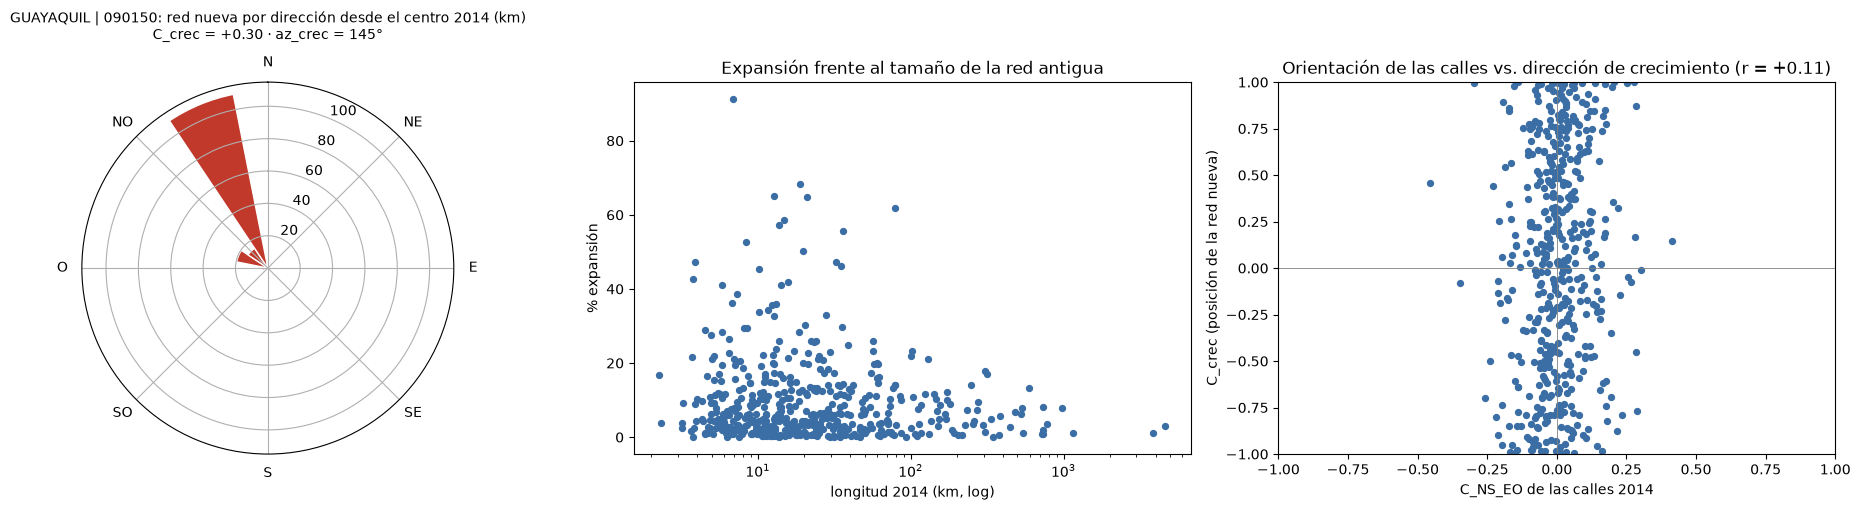

In [26]:
nv = nueva[nueva[CAMPO_GRUPO] == area_m]
d = comp.dropna(subset=["long_km_14", "C_crec"])
r_or = d[["C_NS_EO_14", "C_crec"]].corr().iloc[0, 1]
ancho_c = 360 / N_DIR_CREC

fig = plt.figure(figsize=(19, 5.2))
ax = fig.add_subplot(1, 3, 1, projection="polar")
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
alfa_m = np.degrees(np.arctan2(nv.eda_cx - r14.xm, nv.eda_cy - r14.ym)) % 360
h, _ = np.histogram((alfa_m + ancho_c / 2) % 360, bins=N_DIR_CREC, range=(0, 360), weights=nv.eda_long_m / 1000)
ax.bar(np.radians(np.arange(N_DIR_CREC) * ancho_c), h, width=np.radians(ancho_c), color=COLORES["actual"], edgecolor="white")
ax.set_xticks(np.radians(np.arange(8) * 45)); ax.set_xticklabels(["N", "NE", "E", "SE", "S", "SO", "O", "NO"])
ax.set_title(f"{area_m}: red nueva por dirección desde el centro {ANIOS['antigua']} (km)\n"
             f"C_crec = {comp.loc[area_m, 'C_crec']:+.2f} · az_crec = {comp.loc[area_m, 'az_crec']:.0f}°",
             pad=12, fontsize=10)

ax = fig.add_subplot(1, 3, 2)
ax.scatter(d.long_km_14, d.pct_expansion, s=18, color=COLORES["antigua"])
ax.set(xscale="log", xlabel=f"longitud {ANIOS['antigua']} (km, log)", ylabel="% expansión",
       title="Expansión frente al tamaño de la red antigua")
ax = fig.add_subplot(1, 3, 3)
ax.scatter(d.C_NS_EO_14, d.C_crec, s=18, color=COLORES["antigua"])
ax.axhline(0, color="grey", linewidth=0.6); ax.axvline(0, color="grey", linewidth=0.6)
ax.set(xlabel=f"C_NS_EO de las calles {ANIOS['antigua']}", ylabel="C_crec (posición de la red nueva)",
       xlim=(-1, 1), ylim=(-1, 1), title=f"Orientación de las calles vs. dirección de crecimiento (r = {r_or:+.2f})")
plt.tight_layout(); plt.show()

## 10. Modelos de crecimiento
**Unidad:** área con red en las dos fechas (filas de `comp`). **Predictores:** solo métricas de la versión antigua, de modo que el modelo estima el crecimiento posterior a partir de la forma previa, sin usar información del resultado. **Objetivo:** `OBJETIVO` (sección 1).

- **Regresión lineal** con predictores estandarizados: los coeficientes son comparables entre sí (cambio del objetivo por una desviación estándar del predictor).
- **Random forest:** capta relaciones no lineales e interacciones; `MIN_HOJA` limita el sobreajuste.
- **Referencia:** predice siempre la media de entrenamiento (R² ≈ 0). Un modelo útil debe superarla.

**Evaluación:** partición entrenamiento/prueba (`PRUEBA`) y validación cruzada de `N_PLIEGUES` pliegues sobre todas las áreas. Métricas: R², MAE y RMSE (en las unidades del objetivo). Con pocas áreas, la partición única es inestable; la validación cruzada (media y desviación) es la referencia más confiable.

- `phi` y `H_o` son transformaciones una de la otra; se usa solo `phi`.
- El azimut de la elipse es axial, así que entra como cos 2θ y sin 2θ.
- La longitud y la elongación entran en logaritmo (la elongación tiene cola larga en redes casi lineales).

### 10.1. Ajuste y métricas

In [27]:
datos = comp[comp.long_km_14.notna() & comp.long_km_21.notna()].copy()
datos["log_long_km_14"] = np.log10(datos.long_km_14)
datos["log_elong_14"] = np.log10(datos.elongacion_14)
datos["elip_cos2_14"] = np.cos(np.radians(2 * datos.az_elipse_14))
datos["elip_sin2_14"] = np.sin(np.radians(2 * datos.az_elipse_14))
datos["dens_elipse_14"] = datos.long_km_14 / (np.pi * datos.elip_a_km_14 * datos.elip_b_km_14)   # km/km²

ok = datos[PREDICTORES].notna().all(axis=1) & datos[OBJETIVO].notna()
X, y = datos.loc[ok, PREDICTORES], datos.loc[ok, OBJETIVO]
print(f"Objetivo: {OBJETIVO} | áreas: {len(y)} (de {len(datos)} con las dos versiones) | "
      f"media {y.mean():.3f} · desv. {y.std():.3f}")
if len(y) < 20:
    print("Pocas áreas: las métricas son orientativas; ampliar FILTRO_SQL para más casos")

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=PRUEBA, random_state=SEMILLA)
modelos = {
    "Referencia (media)": DummyRegressor(),
    "Regresión lineal": make_pipeline(StandardScaler(), LinearRegression()),
    "Random forest": RandomForestRegressor(n_estimators=N_ARBOLES, min_samples_leaf=MIN_HOJA,
                                           random_state=SEMILLA, n_jobs=-1),
}
kf = KFold(n_splits=min(N_PLIEGUES, len(y)), shuffle=True, random_state=SEMILLA)
filas, pred = [], {}
for nombre, m in modelos.items():
    m.fit(X_tr, y_tr)
    p_tr, pred[nombre] = m.predict(X_tr), m.predict(X_te)
    cv = cross_validate(m, X, y, cv=kf,
                        scoring=("r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"))
    filas.append({"modelo": nombre,
                  "R² entrenamiento": r2_score(y_tr, p_tr), "R² prueba": r2_score(y_te, pred[nombre]),
                  "MAE prueba": mean_absolute_error(y_te, pred[nombre]),
                  "RMSE prueba": np.sqrt(mean_squared_error(y_te, pred[nombre])),
                  "R² VC media": cv["test_r2"].mean(), "R² VC desv.": cv["test_r2"].std(),
                  "MAE VC": -cv["test_neg_mean_absolute_error"].mean(),
                  "RMSE VC": -cv["test_neg_root_mean_squared_error"].mean()})
metricas = pd.DataFrame(filas).set_index("modelo")
print(f"Entrenamiento: {len(y_tr)} áreas | prueba: {len(y_te)} | validación cruzada: {kf.n_splits} pliegues")
metricas.round(3)

Objetivo: pct_expansion | áreas: 763 (de 763 con las dos versiones) | media 6.199 · desv. 10.597
Entrenamiento: 572 áreas | prueba: 191 | validación cruzada: 5 pliegues


,R² entrenamiento,R² prueba,MAE prueba,RMSE prueba,R² VC media,R² VC desv.,MAE VC,RMSE VC
modelo,,,,,,,,
Referencia (media),0.000,-0.003,6.727,10.246,-0.010,0.012,6.973,10.493
Regresión lineal,0.030,0.008,6.715,10.188,0.002,0.026,6.874,10.419
Random forest,0.757,-0.042,6.953,10.443,-0.055,0.073,7.167,10.687


### 10.2. Interpretación
- **Observado vs. predicho** en el conjunto de prueba: los puntos sobre la diagonal son predicciones exactas.
- **Coeficientes estandarizados** de la regresión lineal: signo y magnitud del efecto de cada predictor.
- **Importancia por permutación** del random forest en prueba: cuánto empeora el R² al desordenar ese predictor. La importancia por impureza se incluye en la tabla, pero tiende a favorecer variables continuas con muchos valores.

,coef_RL_estandarizado,RF_permutación,RF_permutación_desv,RF_impureza
elip_sin2_14,0.086,0.054,0.012,0.097
phi_14,0.822,0.031,0.013,0.091
sinuos_mediana_14,-0.958,0.025,0.022,0.121
log_long_km_14,0.720,0.024,0.023,0.115
dens_elipse_14,-1.054,0.020,0.019,0.135
C_NS_EO_14,0.247,0.017,0.013,0.099
log_elong_14,-0.411,0.000,0.011,0.113
R_14,-0.090,-0.011,0.014,0.104
elip_cos2_14,-0.430,-0.018,0.017,0.124


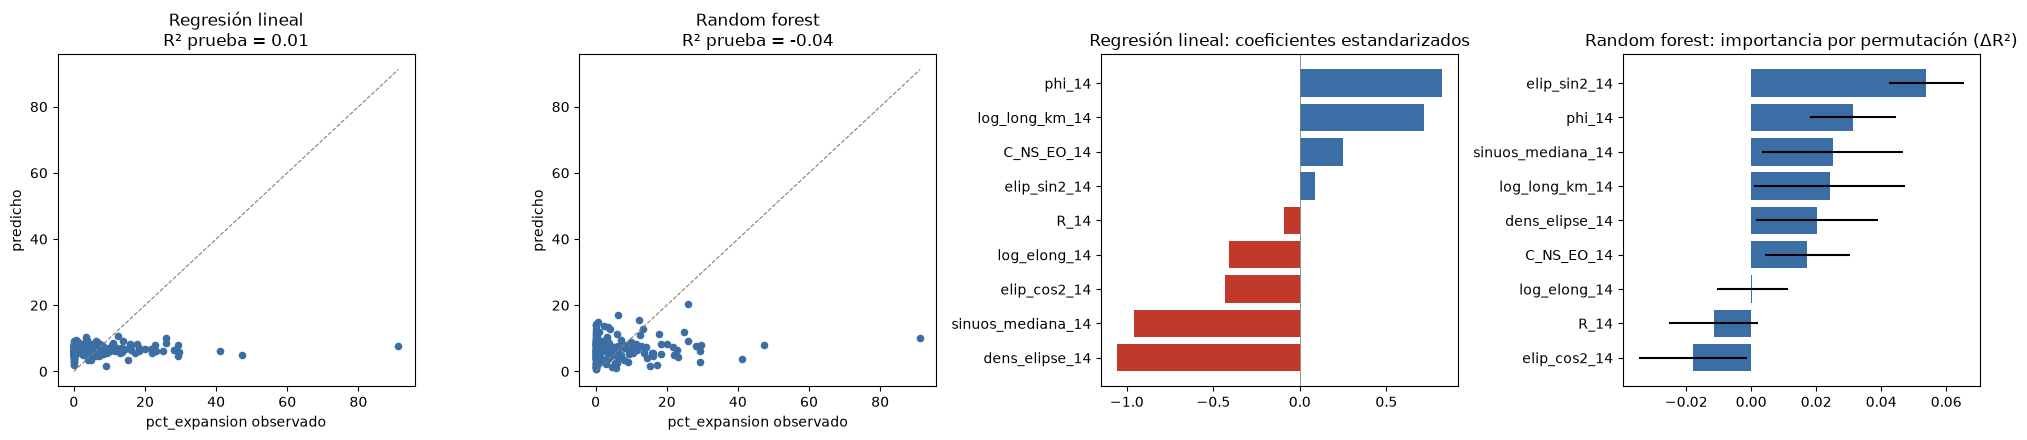

In [28]:
rl, rf = modelos["Regresión lineal"], modelos["Random forest"]
perm = permutation_importance(rf, X_te, y_te, n_repeats=N_PERMUT, random_state=SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"coef_RL_estandarizado": rl[-1].coef_,
                            "RF_permutación": perm.importances_mean, "RF_permutación_desv": perm.importances_std,
                            "RF_impureza": rf.feature_importances_}, index=PREDICTORES)
importancia = importancia.sort_values("RF_permutación", ascending=False)
display(importancia.round(3))

fig, axs = plt.subplots(1, 4, figsize=(20, 4.5))
lim = [min(y.min(), *[p.min() for p in pred.values()]), max(y.max(), *[p.max() for p in pred.values()])]
for ax, nombre in zip(axs[:2], ["Regresión lineal", "Random forest"]):
    ax.scatter(y_te, pred[nombre], s=20, color=COLORES["antigua"])
    ax.plot(lim, lim, color="grey", linestyle="--", linewidth=0.8)
    ax.set(xlabel=f"{OBJETIVO} observado", ylabel="predicho",
           title=f"{nombre}\nR² prueba = {metricas.loc[nombre, 'R² prueba']:.2f}")
c = importancia.coef_RL_estandarizado.sort_values()
axs[2].barh(c.index, c.values, color=np.where(c.values >= 0, COLORES["antigua"], COLORES["actual"]))
axs[2].axvline(0, color="grey", linewidth=0.6); axs[2].set_title("Regresión lineal: coeficientes estandarizados")
p = importancia.RF_permutación.sort_values()
axs[3].barh(p.index, p.values, xerr=importancia.RF_permutación_desv.reindex(p.index), color=COLORES["antigua"])
axs[3].set_title("Random forest: importancia por permutación (ΔR²)")
plt.tight_layout(); plt.show()

### 10.3. Objetivo alternativo: dirección del crecimiento (`C_crec`)
La sección 10.1 pregunta **cuánto** crece un área. Esta celda pregunta **en qué eje** crece, que es lo más cercano a la pregunta del proyecto: `C_crec` = +1 si la red nueva se ubica al N y al S del centro 2014, −1 si se ubica al E y al O. Se usan los mismos predictores, modelos y evaluación que en 10.1.

- Solo entran las áreas con red nueva (`C_crec` no existe sin ella) y con al menos `MIN_KM_NUEVOS` km nuevos: con muy poca red nueva, un solo segmento fija `C_crec` en ±1.
- **Correlación simple** de cada predictor con `C_crec`. Si el crecimiento sigue al eje mayor de la ciudad, `elip_cos2_14` debería tener correlación positiva. Si sigue a la orientación de las calles, la tendría `C_NS_EO_14`.
- **Sensibilidad:** R² de validación cruzada para cada umbral de `UMBRALES_KM`.
- Las variables de esta celda llevan el sufijo `_c`; `modelos`, `metricas` y `pred` de 10.1–10.2 no cambian.

Objetivo: C_crec | áreas: 481 (red nueva ≥ 0 km) | media +0.036 · desv. 0.587
Entrenamiento: 360 áreas | prueba: 121 | validación cruzada: 5 pliegues


,R² entrenamiento,R² prueba,MAE prueba,RMSE prueba,R² VC media,R² VC desv.,MAE VC,RMSE VC
modelo,,,,,,,,
Referencia (media),0.000,-0.064,0.541,0.636,-0.037,0.047,0.506,0.589
Regresión lineal,0.071,0.081,0.501,0.591,0.009,0.085,0.488,0.574
Random forest,0.813,0.073,0.506,0.594,-0.012,0.044,0.486,0.581


,r_con_objetivo,coef_RL_estandarizado,RF_permutación,RF_permutación_desv
elip_cos2_14,0.292,0.128,0.189,0.042
log_long_km_14,0.065,-0.002,0.025,0.015
R_14,-0.053,-0.014,0.015,0.011
sinuos_mediana_14,-0.047,-0.031,0.013,0.014
log_elong_14,0.072,0.043,0.008,0.023
phi_14,-0.070,-0.048,0.007,0.013
elip_sin2_14,0.013,-0.004,0.004,0.008
dens_elipse_14,-0.047,0.042,-0.001,0.021
C_NS_EO_14,0.098,0.016,-0.017,0.018


,áreas,R² VC Regresión lineal,R² VC Random forest
≥ 0 km,481,+0.009 ± 0.085,-0.012 ± 0.044
≥ 0.5 km,348,+0.044 ± 0.048,-0.002 ± 0.034
≥ 1 km,279,-0.073 ± 0.201,-0.124 ± 0.171
≥ 2 km,208,-0.001 ± 0.156,+0.027 ± 0.039


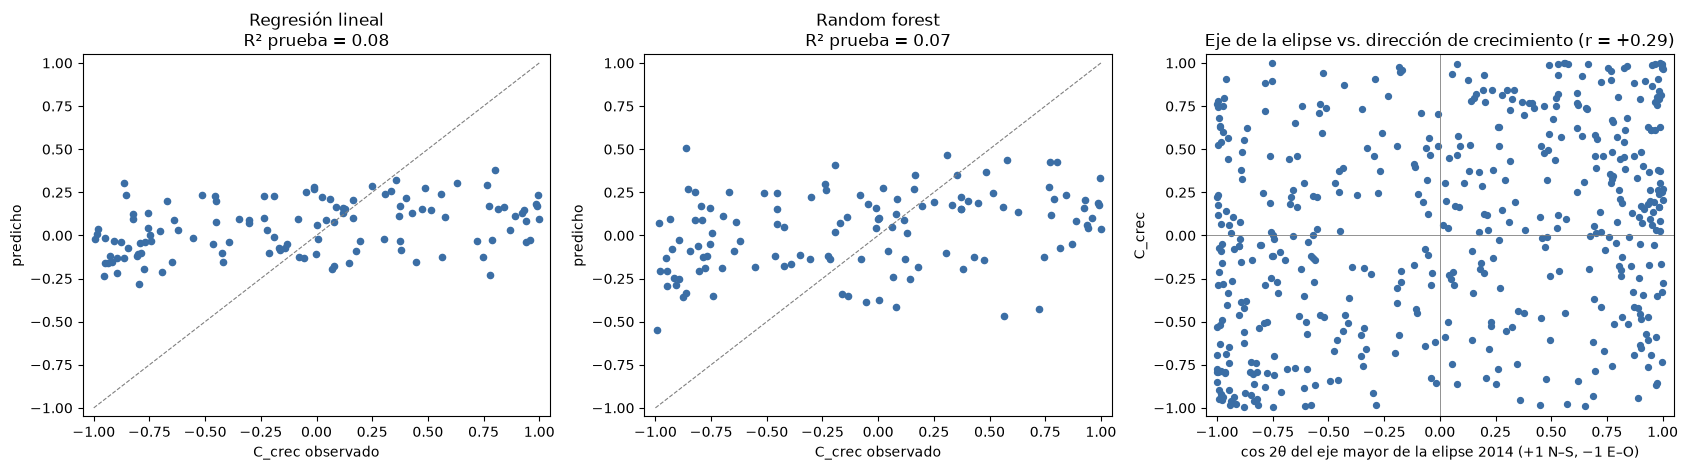

In [29]:
# Modelos con la dirección del crecimiento como objetivo (OBJETIVO_DIR)
ok_c = datos[PREDICTORES].notna().all(axis=1) & datos[OBJETIVO_DIR].notna() & (datos.km_fuera_14 >= MIN_KM_NUEVOS)
X_c, y_c = datos.loc[ok_c, PREDICTORES], datos.loc[ok_c, OBJETIVO_DIR]
print(f"Objetivo: {OBJETIVO_DIR} | áreas: {len(y_c)} (red nueva ≥ {MIN_KM_NUEVOS} km) | "
      f"media {y_c.mean():+.3f} · desv. {y_c.std():.3f}")

X_tr_c, X_te_c, y_tr_c, y_te_c = train_test_split(X_c, y_c, test_size=PRUEBA, random_state=SEMILLA)
modelos_c = {
    "Referencia (media)": DummyRegressor(),
    "Regresión lineal": make_pipeline(StandardScaler(), LinearRegression()),
    "Random forest": RandomForestRegressor(n_estimators=N_ARBOLES, min_samples_leaf=MIN_HOJA,
                                           random_state=SEMILLA, n_jobs=-1),
}
kf_c = KFold(n_splits=min(N_PLIEGUES, len(y_c)), shuffle=True, random_state=SEMILLA)
filas_c, pred_c = [], {}
for nombre, m in modelos_c.items():
    m.fit(X_tr_c, y_tr_c)
    p_tr, pred_c[nombre] = m.predict(X_tr_c), m.predict(X_te_c)
    cv = cross_validate(m, X_c, y_c, cv=kf_c,
                        scoring=("r2", "neg_mean_absolute_error", "neg_root_mean_squared_error"))
    filas_c.append({"modelo": nombre,
                    "R² entrenamiento": r2_score(y_tr_c, p_tr), "R² prueba": r2_score(y_te_c, pred_c[nombre]),
                    "MAE prueba": mean_absolute_error(y_te_c, pred_c[nombre]),
                    "RMSE prueba": np.sqrt(mean_squared_error(y_te_c, pred_c[nombre])),
                    "R² VC media": cv["test_r2"].mean(), "R² VC desv.": cv["test_r2"].std(),
                    "MAE VC": -cv["test_neg_mean_absolute_error"].mean(),
                    "RMSE VC": -cv["test_neg_root_mean_squared_error"].mean()})
metricas_c = pd.DataFrame(filas_c).set_index("modelo")
print(f"Entrenamiento: {len(y_tr_c)} áreas | prueba: {len(y_te_c)} | validación cruzada: {kf_c.n_splits} pliegues")
display(metricas_c.round(3))

# Correlación simple, coeficientes e importancia por permutación
rl_c, rf_c = modelos_c["Regresión lineal"], modelos_c["Random forest"]
perm_c = permutation_importance(rf_c, X_te_c, y_te_c, n_repeats=N_PERMUT, random_state=SEMILLA, n_jobs=-1)
importancia_c = pd.DataFrame({"r_con_objetivo": X_c.corrwith(y_c), "coef_RL_estandarizado": rl_c[-1].coef_,
                              "RF_permutación": perm_c.importances_mean, "RF_permutación_desv": perm_c.importances_std},
                             index=PREDICTORES).sort_values("RF_permutación", ascending=False)
display(importancia_c.round(3))

# Sensibilidad del R² de validación cruzada al umbral de red nueva
sens_c = {}
for umbral in UMBRALES_KM:
    ok_u = datos[PREDICTORES].notna().all(axis=1) & datos[OBJETIVO_DIR].notna() & (datos.km_fuera_14 >= umbral)
    fila = {"áreas": int(ok_u.sum())}
    for nombre in ["Regresión lineal", "Random forest"]:
        r2_u = cross_validate(modelos_c[nombre], datos.loc[ok_u, PREDICTORES], datos.loc[ok_u, OBJETIVO_DIR],
                              cv=KFold(n_splits=min(N_PLIEGUES, int(ok_u.sum())), shuffle=True, random_state=SEMILLA),
                              scoring="r2")["test_score"]
        fila[f"R² VC {nombre}"] = f"{r2_u.mean():+.3f} ± {r2_u.std():.3f}"
    sens_c[f"≥ {umbral} km"] = fila
display(pd.DataFrame(sens_c).T)

# Gráficos: observado vs. predicho y relación con la dirección de la elipse
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, nombre in zip(axs[:2], ["Regresión lineal", "Random forest"]):
    ax.scatter(y_te_c, pred_c[nombre], s=20, color=COLORES["antigua"])
    ax.plot([-1, 1], [-1, 1], color="grey", linestyle="--", linewidth=0.8)
    ax.set(xlim=(-1.05, 1.05), ylim=(-1.05, 1.05), xlabel=f"{OBJETIVO_DIR} observado", ylabel="predicho",
           title=f"{nombre}\nR² prueba = {metricas_c.loc[nombre, 'R² prueba']:.2f}")
axs[2].scatter(X_c.elip_cos2_14, y_c, s=18, color=COLORES["antigua"])
axs[2].axhline(0, color="grey", linewidth=0.6); axs[2].axvline(0, color="grey", linewidth=0.6)
axs[2].set(xlim=(-1.05, 1.05), ylim=(-1.05, 1.05), xlabel="cos 2θ del eje mayor de la elipse 2014 (+1 N–S, −1 E–O)",
           ylabel=OBJETIVO_DIR, title=f"Eje de la elipse vs. dirección de crecimiento "
                                      f"(r = {importancia_c.loc['elip_cos2_14', 'r_con_objetivo']:+.2f})")
plt.tight_layout(); plt.show()

## 11. Conclusiones

1. **Insumos.** Las dos capas son geométricamente limpias. La versión 2014 no tiene geometrías inválidas. La 2021 tiene una inválida, un duplicado y 1 705 multipartes, que se resuelven con `line_merge` + `explode` (608 882 ejes → 610 658 segmentos). Con la clave `nom_aman | parroq` desaparecen los homónimos: el desplazamiento máximo de un centro entre fechas pasa de 297 km (v5) a 4,8 km. Las bases difieren en el nivel de detalle: la 2021 tiene segmentos más cortos (mediana 66 m frente a 78 m), el doble de segmentos < 5 m y más tipos de eje (24 frente a 18). Por eso, parte del aumento de longitud se debe a la digitalización y no a la construcción de vías.
2. **Orientación (forma).** A escala nacional la red es isotrópica en ambas fechas (φ = 0,012; anisotropía +0,01), porque las orientaciones de ciudades distintas se anulan entre sí. Por área, el orden es moderado (φ mediana 0,44 en 2014 y 0,42 en 2021) y la componente N–S/E–O es casi nula (`C_NS_EO` mediana ≈ 0). Ninguna ciudad grande tiene un predominio de calles N–S sobre E–O. La orientación es estable entre fechas (Guayaquil: φ 0,049 → 0,046).
3. **Extensión.** La elipse y los sectores sí identifican el eje sobre el que se alarga una ciudad. Guayaquil se extiende en el eje N–S (NNO–SSE): eje mayor a 160°, a/b = 1,80 → 1,74, alcance P95 de 16,2 km en N–S frente a 11,4 km en E–O (índice +0,17). La forma se mantiene entre 2014 y 2021. La red nueva se concentra al NO, entre 10 y 13 km del centro, en una dirección cercana al eje mayor.
4. **Crecimiento 2014–2021.** En el marco común, la longitud vial crece 25,2 % (42 190 → 52 835 km). Solo 4 897 km (9,3 % de la red actual, 46 % del incremento) están fuera de la mancha 2014; el resto del aumento ocurre dentro de ella (densificación y diferencias de levantamiento). La expansión es menor cuanto mayor es la red: 1–3 % en las ciudades grandes, frente a los valores más altos en parroquias periurbanas (Llano Chico y Tumbaco en Quito; Totoras y Huachi Grande en Ambato). Además, 378 áreas no tenían red en 2014.
5. **Orientación frente a dirección de crecimiento.** No hay relación entre hacia dónde apuntan las calles y hacia dónde crece la red nueva (r = +0,11). Las direcciones de crecimiento se reparten casi por igual entre clases (NE–SO 138, N–S 135, E–O 115, NO–SE 109 áreas).
6. **Modelos.** Con 763 áreas, ningún modelo supera a la referencia en validación cruzada (R²: regresión lineal 0,002; random forest −0,055; referencia −0,010). El random forest sobreajusta (R² de entrenamiento 0,76). Como el modelo no explica varianza, los coeficientes de la regresión no deben leerse como efectos. La forma de la red en 2014, por sí sola, no permite predecir la expansión posterior.

**Respuesta a la pregunta.** La *orientación* de las calles describe la forma interna de la red, pero **no** indica el eje de extensión ni anticipa hacia dónde ni cuánto crecerá la ciudad.

**Trabajo futuro.**
- Medir la red nueva por geometría (ejes 2021 sin un eje 2014 a menos de X m) en lugar de con las delimitaciones.
- Incorporar variables externas: población censal, pendiente, distancia a vías principales y suelo disponible.
- Tratar el exceso de ceros del objetivo: 266 de las 763 áreas no tienen expansión, lo que sugiere un modelo en dos partes (si crece y cuánto crece) o un modelo por celda en lugar de por área.